# Question 8 — Predicting Stress Level and Mental-Health Score

**Our research question:** can we predict a user's stress level and mental-health score from their
social-media usage characteristics?

**Our two targets:**

| Column | Type | Direction |
|---|---|---|
| `Stress_Level` | 4 ordered levels: `Low` < `Medium` < `High` < `Very High` | higher = worse |
| `Mental_Health_Score` | continuous, 3.6–9.4 | higher = better |

**The models from our proposal.** For classification: Logistic Regression, Random Forest, KNN, XGBoost,
SVM, Ensemble (we test both soft and hard voting), and MLP. For regression: Linear Regression, Random
Forest, KNN, SVR and MLP. We also add a baseline to each table so we can see how much each model
actually gains over doing nothing.

We compare the classifiers on **accuracy, precision, recall, F1 and an AUROC curve for each model**, and
the regressors on **MSE, RMSE, MAE and R²**.

## 1. What we expect to find

The main question: **Which model has the best results?**

Before running anything we wrote down what we expected:

1. **The features should predict both targets**, clearly better than something that ignores them. We put
   a majority-class baseline (0.3243) and a mean baseline (R² ≈ 0) in every table so the gain is visible.
2. **The non-linear models should beat the linear ones**, because we do not think the relationship
   between usage and stress is a straight line.
3. **The tree-based classifiers — Random Forest and XGBoost — should score highest.** Our features mix
   numeric columns (usage hours, unlocks, sleep) with one-hot categorical ones (purpose, platform), the
   patterns we saw in our earlier exploration looked stepped rather than smooth, and trees handle that
   kind of data without us transforming anything first.

We check all three below. One thing to keep in mind while reading our tables: our test set has 1 000
students, so **0.001 of accuracy is a single student**. We do not treat gaps that small as real
differences between models, and we say so where they come up.

## 2. How we did it

### 2.1 The data

We use `dataset/student_social_media_cleaned.csv` — 4 998 students, 13 columns, no missing values. The
cleaning is in `data_exploration/01`: we dropped 2 duplicate rows and clipped 10 small negative values in
`Physical_Activity_Hours` to zero.

We encode stress as 0–3 in `Stress_Level_Enc`, the same convention we used in earlier. Everything is seeded with `RANDOM_STATE = 42` so the notebook gives the same numbers every run.

In [166]:
import os
import time
import warnings
warnings.filterwarnings('ignore')
# Worker processes started by n_jobs=-1 do not inherit the filter set above, and this
# environment's BLAS emits a flood of harmless matmul warnings from inside them.
os.environ['PYTHONWARNINGS'] = 'ignore'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              VotingClassifier)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report,
                             confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_recall_fscore_support,
                             r2_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC, SVR

np.seterr(all='ignore')  # this environment's BLAS emits spurious matmul warnings
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
pd.set_option('display.width', 250)  # keep the wide result tables on one line
pd.set_option('display.max_columns', 50)
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    XGB_LABEL = 'XGBoost'
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False
    XGB_LABEL = 'Gradient Boosting (HistGB — XGBoost not installed)'

# Cleaned dataset exported by data_exploration/01_data_overview_and_distributions.ipynb
# (exact duplicate rows removed, negative values clipped to 0)
DATA_PATH = '../dataset/student_social_media_cleaned.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'{DATA_PATH} not found — run data_exploration/01_data_overview_and_distributions.ipynb first'
    )
df = pd.read_csv(DATA_PATH)

STRESS_ORDER = ['Low', 'Medium', 'High', 'Very High']
df['Stress_Level'] = pd.Categorical(df['Stress_Level'], categories=STRESS_ORDER, ordered=True)

# Ordinal encoding of stress (0..3) — same convention as data_exploration/02 and Questions/02, 07
stress_map = {lvl: i for i, lvl in enumerate(STRESS_ORDER)}
df['Stress_Level_Enc'] = df['Stress_Level'].map(stress_map).astype(int)

STRESS_COL = 'Stress_Level'
STRESS_ENC = 'Stress_Level_Enc'
MHS_COL    = 'Mental_Health_Score'
N_CLASSES  = len(STRESS_ORDER)
STRESS_PALETTE = sns.color_palette('YlOrRd', 4)

print(f'Shape: {df.shape}')
print(f'Boosting backend: {XGB_LABEL}')
print('\nStress level counts (the classification target):')
counts = df[STRESS_COL].value_counts().reindex(STRESS_ORDER)
print(pd.DataFrame({'n': counts, 'share': (counts / len(df)).round(4)}).to_string())
print(f'\nMajority-class baseline accuracy: {counts.max() / len(df):.4f}')
print(f'\n{MHS_COL} (the regression target): '
      f'{df[MHS_COL].min():.1f} to {df[MHS_COL].max():.1f}, '
      f'mean {df[MHS_COL].mean():.3f}, SD {df[MHS_COL].std():.4f}')

Shape: (4998, 14)
Boosting backend: XGBoost

Stress level counts (the classification target):
                 n   share
Stress_Level              
Low            643  0.1287
Medium        1295  0.2591
High          1439  0.2879
Very High     1621  0.3243

Majority-class baseline accuracy: 0.3243

Mental_Health_Score (the regression target): 3.6 to 9.4, mean 6.231, SD 1.2785


### 2.2 Splitting the data

We draw the split once on row indices and reuse the same students for both the classification and the
regression task, so the two halves of our question are answered on exactly the same people. We stratify
on stress, so we also check that the continuous target did not drift between the splits.

In [167]:
TEST_SIZE, VAL_SIZE = 0.20, 0.20          # 60 / 20 / 20

y4     = df[STRESS_ENC].to_numpy()
y_reg  = df[MHS_COL].to_numpy()
idx_all = np.arange(len(df))

idx_fit, idx_test = train_test_split(
    idx_all, test_size=TEST_SIZE, stratify=y4, random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(
    idx_fit, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y4[idx_fit],
    random_state=RANDOM_STATE)

# The split must be a genuine partition — this is the single worst bug available here,
# so it is checked rather than assumed.
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df), 'splits do not cover the data'
assert not (set(idx_train) & set(idx_val)), 'train/val overlap'
assert not (set(idx_train) & set(idx_test)), 'train/test overlap'
assert not (set(idx_val) & set(idx_test)), 'val/test overlap'

split_tbl = pd.DataFrame({
    'Full data': pd.Series(y4).value_counts(normalize=True),
    'Train':     pd.Series(y4[idx_train]).value_counts(normalize=True),
    'Validation': pd.Series(y4[idx_val]).value_counts(normalize=True),
    'Test':      pd.Series(y4[idx_test]).value_counts(normalize=True),
}).sort_index()
split_tbl.index = STRESS_ORDER

# Stratification should hold each class share to well within a percentage point.
assert (split_tbl.sub(split_tbl['Full data'], axis=0).abs().max().max() < 0.01), \
    'stratification failed — class shares drifted between splits'

print(f'Split sizes: train {len(idx_train):,} | validation {len(idx_val):,} | test {len(idx_test):,}')
print('\nClass shares by split (stratified, so these should all agree):')
print(split_tbl.round(4).to_string())
print('\nTest-set support per class:')
print(pd.Series(y4[idx_test]).value_counts().sort_index()
        .rename(lambda i: STRESS_ORDER[i]).to_string())

# The split was stratified on stress, not on the continuous outcome — so check that the
# regression target did not drift as a side effect.
print(f'\n{MHS_COL} by split (the regression target, stratified only indirectly):')
print(pd.DataFrame({
    'mean': [y_reg[i].mean() for i in (idx_train, idx_val, idx_test)],
    'SD':   [y_reg[i].std()  for i in (idx_train, idx_val, idx_test)],
}, index=['Train', 'Validation', 'Test']).round(4).to_string())

Split sizes: train 2,998 | validation 1,000 | test 1,000

Class shares by split (stratified, so these should all agree):
           Full data   Train  Validation   Test
Low           0.1287  0.1284       0.129  0.129
Medium        0.2591  0.2592       0.259  0.259
High          0.2879  0.2879       0.288  0.288
Very High     0.3243  0.3245       0.324  0.324

Test-set support per class:
Low          129
Medium       259
High         288
Very High    324

Mental_Health_Score by split (the regression target, stratified only indirectly):
              mean      SD
Train       6.2300  1.2866
Validation  6.2540  1.2441
Test        6.2117  1.2868


In [168]:
# Set A is the literal wording of the research proposal: usage characteristics only.
USAGE_NUM = ['Avg_Daily_Usage_Hours', 'Daily_Unlocks']
USAGE_CAT = ['Purpose_Of_Use', 'Most_Used_Platform']

# Set B adds lifestyle and demographics — the primary feature set.
FULL_NUM = ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
            'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']
FULL_CAT = ['Gender', 'Academic_Level', 'Purpose_Of_Use', 'Most_Used_Platform']


def build_X(num_cols, cat_cols, extra_cat=()):
    """One-hot the categoricals and return a float design matrix (repo convention: Q2 §5)."""
    parts = [df[num_cols].astype(float)]
    cats = list(cat_cols) + list(extra_cat)
    if cats:
        parts.append(pd.get_dummies(df[cats], drop_first=True).astype(float))
    X = pd.concat(parts, axis=1)
    assert X.notna().all().all(), 'NaN in the design matrix'
    return X


X_usage = build_X(USAGE_NUM, USAGE_CAT)
X_full  = build_X(FULL_NUM, FULL_CAT)

# --- Leakage guards, as executable asserts ------------------------------------
# Stress and mental-health score are both OUTCOMES of Q8. Neither may be a feature.
for name, X in [('Set A', X_usage), ('Set B', X_full)]:
    banned = {MHS_COL, STRESS_COL, STRESS_ENC, 'High_Stress'}
    assert not (banned & set(X.columns)), f'{name} contains an outcome as a feature'
    assert not any(c.startswith(('Stress_Level', 'Mental_Health')) for c in X.columns), \
        f'{name} contains an outcome-derived dummy'

print(f'\nSet A — usage only        : {X_usage.shape[1]} columns')
print(f'  {list(X_usage.columns)}')
print(f'\nSet B — usage + lifestyle + demographics (primary): {X_full.shape[1]} columns')
print(f'  {list(X_full.columns)}')
print(f'\nExcluded from both by design: {MHS_COL} and {STRESS_COL} (both are outcomes), '
      f'Country (111 levels, see below)')


Set A — usage only        : 16 columns
  ['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Purpose_Of_Use_Entertainment', 'Purpose_Of_Use_Networking', 'Purpose_Of_Use_News', 'Most_Used_Platform_Instagram', 'Most_Used_Platform_KakaoTalk', 'Most_Used_Platform_LINE', 'Most_Used_Platform_LinkedIn', 'Most_Used_Platform_Snapchat', 'Most_Used_Platform_TikTok', 'Most_Used_Platform_Twitter', 'Most_Used_Platform_VKontakte', 'Most_Used_Platform_WeChat', 'Most_Used_Platform_WhatsApp', 'Most_Used_Platform_YouTube']

Set B — usage + lifestyle + demographics (primary): 23 columns
  ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Gender_Male', 'Academic_Level_High School', 'Academic_Level_Undergraduate', 'Purpose_Of_Use_Entertainment', 'Purpose_Of_Use_Networking', 'Purpose_Of_Use_News', 'Most_Used_Platform_Instagram', 'Most_Used_Platform_KakaoTalk', 'Most_Used_Platform_LINE', 'Most_Used_Platform_LinkedIn', 'Most_Used_Platform_Snapchat', 

### 2.3 Building the features, and keeping the targets out of them

We build two feature sets. **Set A** is only the usage columns — daily hours, daily unlocks, purpose of
use and platform — which is 16 features after one-hot encoding, and it matches the exact wording of our
question. **Set B** adds sleep, study and activity hours plus age, gender and academic level, giving 23
features. Set B is our main feature set.

We leave `Country` out of both sets: 1 879 students are already labelled `Other`, most countries have
under 20 students, and in `data_exploration/02` no country dummy made our top-5 feature ranking. We test
this decision in section 3.5.

**Keeping the targets separate.** `Stress_Level` and `Mental_Health_Score` are *both* targets in these models, so
we never use one to predict the other. They are two self-reports of the same thing, and predicting one
from the other would just be contaminating the data. We also create normalization of the data with Standard scalar.

In [169]:
leak_rows = []
for label, est in [('Random Forest', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
                   ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]:
    for variant, X in [('without Mental_Health_Score (used everywhere below)', X_full),
                       ('with Mental_Health_Score (leaky — for illustration only)',
                        pd.concat([X_full, df[[MHS_COL]].astype(float)], axis=1))]:
        pipe = Pipeline([('scaler', StandardScaler()), ('model', clone(est))])
        pipe.fit(X.iloc[idx_train], y4[idx_train])
        leak_rows.append({
            'Model': label,
            'Feature matrix': variant,
            'Validation accuracy': round(pipe.score(X.iloc[idx_val], y4[idx_val]), 4),
        })

leak_df = pd.DataFrame(leak_rows)
print('Does adding the other outcome help predict stress?')
print(leak_df.to_string(index=False))

delta = (leak_df.groupby('Model', sort=False)['Validation accuracy']
                .agg(lambda s: s.iloc[1] - s.iloc[0]))
print('\nGain from adding Mental_Health_Score:')
for m, d in delta.items():
    print(f'  {m:<20} {d:+.4f}')

Does adding the other outcome help predict stress?
              Model                                           Feature matrix  Validation accuracy
      Random Forest      without Mental_Health_Score (used everywhere below)                0.849
      Random Forest with Mental_Health_Score (leaky — for illustration only)                0.842
Logistic Regression      without Mental_Health_Score (used everywhere below)                0.723
Logistic Regression with Mental_Health_Score (leaky — for illustration only)                0.729

Gain from adding Mental_Health_Score:
  Random Forest        -0.0070
  Logistic Regression  +0.0060


#### 2.3.1 Checking that this rule does not cost us anything

A rule that costs accuracy is a rule we might be tempted to break later, so we measured it. Adding
`Mental_Health_Score` to the features changes validation accuracy by **−0.0070** for Random Forest
(0.849 → 0.842) and **+0.0060** for Logistic Regression (0.723 → 0.729). For the random forest it
actually makes things slightly *worse*, and both changes are very little changes in classification results either way.

The reason is interesting on its own: the mental-health score is almost a fixed function of columns we
already have as we demonstrate in this research.

### 2.5 The models and how we tuned them

Every model sits in the same pipeline: standardise, then fit. KNN, SVM, MLP and logistic regression
really need the scaling — `Daily_Unlocks` goes from 62 to 273 while `Physical_Activity_Hours` goes from 0
to 4.1, so without scaling the unlocks would dominate every distance. The tree models do not need it, but
scaling each column separately cannot change where a tree splits, so we use one pipeline for everything
and keep the code simple.

For the two ensembles we reuse clones of the individual models *after* they were tuned, so the ensemble
members always match the tuning results we report in 3.1 and 3.2.

In [170]:
# --- Tuning split: one explicit validation fold, no K-fold --------------------
# -1 marks training rows (never scored on), 0 marks the single validation fold.
_test_fold = np.full(len(idx_fit), -1)
_test_fold[np.isin(idx_fit, idx_val)] = 0
VAL_SPLIT = PredefinedSplit(_test_fold)
assert VAL_SPLIT.get_n_splits() == 1, 'expected exactly one validation fold'

def make_pipe(est):
    return Pipeline([('scaler', StandardScaler()), ('model', est)])


def xgb_classifier():
    if HAS_XGB:
        return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                             subsample=0.9, colsample_bytree=0.9, tree_method='hist',
                             eval_metric='mlogloss', n_jobs=-1, random_state=RANDOM_STATE)
    return HistGradientBoostingClassifier(random_state=RANDOM_STATE)


XGB_GRID = ({'model__max_depth': [0]+ list(range(1, 30, 5)), 'model__learning_rate': [0.1, 0.3, 0.5, 0.7]} if HAS_XGB
            else {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [31, 63]})

# Penalty type is tuned alongside C, but not every solver supports every penalty: lbfgs
# handles l2 and no-penalty only, while saga is the one solver that also covers l1 and
# elasticnet on a multi-class target. So the grid is a LIST of blocks — GridSearchCV
# searches each block separately, which means an invalid solver/penalty pair is never
# built. Without a penalty C does nothing, so that block leaves C at its default.
LOGREG_GRID = [
    {'model__solver': ['lbfgs'], 'model__penalty': ['l2'],
     'model__C': [0.1, 1, 10]},
    {'model__solver': ['saga'],  'model__penalty': ['l1'],
     'model__C': [0.1, 1, 10]},
    {'model__solver': ['saga'],  'model__penalty': ['elasticnet'],
     'model__C': [0.1, 1, 10], 'model__l1_ratio': [0.15, 0.5, 0.85]},
    {'model__solver': ['lbfgs'], 'model__penalty': [None]},
]

# The seven individual candidates plus a baseline. The two voting ensembles are built
# further down from whichever configurations actually win here, so the ensemble is
# self-consistent with the tuning rather than using hard-coded members.
BASE_MODELS = [
    ('Baseline (majority)', DummyClassifier(strategy='most_frequent'), {}),
    ('Logistic Regression', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        LOGREG_GRID),
    ('KNN', KNeighborsClassifier(n_jobs=-1),
        {'model__n_neighbors': range(1, 31), 'model__weights': ['uniform', 'distance'],
         'model__metric': ['euclidean', 'manhattan', 'chebyshev']}),
    ('Random Forest', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {'model__n_estimators': range(100,501,100), 'model__max_depth': [None]+ list(range(1, 30, 5)),
         'model__min_samples_leaf': range(1,11,2)}),
    (XGB_LABEL, xgb_classifier(), XGB_GRID),
    ('SVM (RBF)', SVC(probability=True, cache_size=1000, random_state=RANDOM_STATE),
        {'model__C': [1, 10, 100], 'model__gamma': ['scale', 0.1]}),
    ('MLP (neural net)', MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
        {'model__hidden_layer_sizes': [(64, 32), (128, 64)], 'model__alpha': [1e-4, 1e-2]}),
]
# Members for the voting ensembles, drawn from the tuned individual models above.
VOTE_MEMBER_KEYS = ['Logistic Regression', 'KNN', 'Random Forest', 'SVM (RBF)', 'MLP (neural net)']

def grid_summary(grid):
    """Tuned parameter names and candidate count for a dict OR a list of grid blocks.

    For a list the candidates SUM across blocks, rather than forming one product.
    """
    blocks = grid if isinstance(grid, list) else [grid]
    names = list(dict.fromkeys(k.replace('model__', '') for b in blocks for k in b))
    points = sum(int(np.prod([len(v) for v in b.values()])) if b else 1 for b in blocks)
    return ', '.join(names) or '—', max(1, points)


roster_rows = []
for n, _, g in BASE_MODELS:
    tuned, points = grid_summary(g)
    roster_rows.append({'Model': n, 'Tuned parameters': tuned, 'Grid points': points})
roster_rows += [{'Model': f'Ensemble ({v} vote)',
                 'Tuned parameters': 'members inherit their tuned settings',
                 'Grid points': 1} for v in ('soft', 'hard')]
roster = pd.DataFrame(roster_rows)
print('Classification roster:')
print(roster.to_string(index=False))
print(f'\nTuning: {len(idx_train):,} train rows scored on {len(idx_val):,} validation rows, '
      f'then refit on all {len(idx_fit):,}; {len(idx_test):,} test rows held back.')

Classification roster:
               Model                          Tuned parameters  Grid points
 Baseline (majority)                                         —            1
 Logistic Regression              solver, penalty, C, l1_ratio           16
                 KNN              n_neighbors, weights, metric          180
       Random Forest n_estimators, max_depth, min_samples_leaf          175
             XGBoost                  max_depth, learning_rate           28
           SVM (RBF)                                  C, gamma            6
    MLP (neural net)                 hidden_layer_sizes, alpha            4
Ensemble (soft vote)      members inherit their tuned settings            1
Ensemble (hard vote)      members inherit their tuned settings            1

Tuning: 2,998 train rows scored on 1,000 validation rows, then refit on all 3,998; 1,000 test rows held back.


In [171]:
def evaluate_classifier(label, est, grid, X, y):
    """Tune on the validation split, refit on train+val, score once on the test set."""
    t0 = time.perf_counter()
    search = GridSearchCV(make_pipe(clone(est)), grid, cv=VAL_SPLIT,
                          scoring='accuracy', n_jobs=-1, refit=True)
    search.fit(X.iloc[idx_fit], y[idx_fit])
    fitted = search.best_estimator_

    X_te, y_te = X.iloc[idx_test], y[idx_test]
    # Hard voting has no predict_proba, so it has no ROC curve and no AUC. That is
    # reported as a missing value rather than papered over.
    proba = fitted.predict_proba(X_te) if hasattr(fitted, 'predict_proba') else None
    pred = proba.argmax(axis=1) if proba is not None else fitted.predict(X_te)
    elapsed = time.perf_counter() - t0

    if proba is not None:
        assert proba.shape[1] == N_CLASSES, 'a fold is missing a class — probabilities misaligned'

    p_ma, r_ma, f_ma, _ = precision_recall_fscore_support(
        y_te, pred, average='macro', zero_division=0)
    f_wt = f1_score(y_te, pred, average='weighted', zero_division=0)

    row = {
        'Model': label,
        'Accuracy': round(accuracy_score(y_te, pred), 4),
        'Balanced Acc': round(balanced_accuracy_score(y_te, pred), 4),
        'Precision (macro)': round(p_ma, 4),
        'Recall (macro)': round(r_ma, 4),
        'F1 (macro)': round(f_ma, 4),
        'F1 (weighted)': round(f_wt, 4),
        'ROC-AUC (macro OvR)': (round(roc_auc_score(y_te, proba, multi_class='ovr',
                                                    average='macro'), 4)
                                if proba is not None else np.nan),
        'Best params': (', '.join(f'{k.replace("model__", "")}={v}'
                                  for k, v in search.best_params_.items()) or '—'),
        'Fit time (s)': round(elapsed, 1),
    }
    return row, pred, proba, fitted, search


def run_roster(X, y, set_label):
    """Run the seven candidates, then build both voting ensembles from the winners."""
    rows, preds, probas, fitted_models = [], {}, {}, {}
    for label, est, grid in BASE_MODELS:
        row, pred, proba, fitted, _ = evaluate_classifier(label, est, grid, X, y)
        rows.append(row); preds[label] = pred; probas[label] = proba
        fitted_models[label] = fitted
        print(f'  {set_label} | {label:<45} acc {row["Accuracy"]:.4f}  '
              f'({row["Fit time (s)"]:>5.1f}s)  {row["Best params"]}')

    # Both ensembles share an identical member list drawn from the tuned pipelines above,
    # so the ONLY difference between the two rows is the combination rule.
    members = [(k.split()[0].lower(), clone(fitted_models[k])) for k in VOTE_MEMBER_KEYS]
    for voting in ('soft', 'hard'):
        label = f'Ensemble ({voting} vote)'
        row, pred, proba, fitted, _ = evaluate_classifier(
            label, VotingClassifier(members, voting=voting, n_jobs=-1), {}, X, y)
        rows.append(row); preds[label] = pred; probas[label] = proba
        fitted_models[label] = fitted
        print(f'  {set_label} | {label:<45} acc {row["Accuracy"]:.4f}  '
              f'({row["Fit time (s)"]:>5.1f}s)')

    results = pd.DataFrame(rows)
    return results, preds, probas, fitted_models


MODEL_ORDER = [n for n, _, _ in BASE_MODELS] + ['Ensemble (soft vote)', 'Ensemble (hard vote)']
MODEL_COLORS = dict(zip(MODEL_ORDER, sns.color_palette('tab10', len(MODEL_ORDER))))
y_test = y4[idx_test]
print(f'Helper functions ready. {len(MODEL_ORDER)} models per feature set.')

Helper functions ready. 9 models per feature set.


In [172]:
# --- Figure helpers: the same three views, so Set A and Set B are directly ----
# --- comparable rather than each being drawn its own way ---------------------
Y_BIN = label_binarize(y_test, classes=list(range(N_CLASSES)))
CLASS_SUPPORT = pd.Series(y_test).value_counts().reindex(range(N_CLASSES))


def plot_headline_bars(res, set_label):
    """Accuracy, macro F1 and macro AUC per model, against the majority baseline."""
    plot_df = (res.set_index('Model').loc[[m for m in MODEL_ORDER]]
               [['Accuracy', 'F1 (macro)', 'ROC-AUC (macro OvR)']])
    baseline = res.loc[res['Model'] == 'Baseline (majority)', 'Accuracy'].iat[0]

    fig, ax = plt.subplots(figsize=(11, 7))
    ypos = np.arange(len(plot_df))[::-1]
    h = 0.26
    for off, (col, color) in zip((h, 0, -h), [('Accuracy', 'steelblue'),
                                              ('F1 (macro)', 'teal'),
                                              ('ROC-AUC (macro OvR)', 'darkorange')]):
        vals = plot_df[col].to_numpy(dtype=float)
        ax.barh(ypos + off, np.nan_to_num(vals), height=h, color=color, edgecolor='white',
                label=col)
        for yv, v in zip(ypos + off, vals):
            ax.text(0.008, yv, 'n/a' if np.isnan(v) else f'{v:.3f}', va='center',
                    ha='left', fontsize=8, color='white' if not np.isnan(v) else 'crimson')

    ax.axvline(baseline, color='crimson', linestyle='--', linewidth=1.3,
               label=f'Majority baseline ({baseline:.3f})')
    ax.set_yticks(ypos); ax.set_yticklabels(plot_df.index)
    ax.set_xlabel('Score'); ax.set_xlim(0, 1.02)
    ax.set_title(f'{set_label} — Model Comparison on the Held-Out Test Set')
    ax.legend(loc='lower right', fontsize=9)
    plt.tight_layout(); plt.show()


def plot_confusions(preds, res, set_label):
    """Confusion matrix per model, in student counts on one shared colour scale."""
    cms = {m: confusion_matrix(y_test, preds[m], labels=range(N_CLASSES))
           for m in MODEL_ORDER}
    cm_vmax = max(cm.max() for cm in cms.values())

    fig, axes = plt.subplots(3, 3, figsize=(17, 14))
    for ax, m in zip(axes.ravel(), MODEL_ORDER):
        sns.heatmap(cms[m], ax=ax, annot=True, fmt='d', cmap='YlOrRd', vmin=0, vmax=cm_vmax,
                    cbar=False, xticklabels=STRESS_ORDER, yticklabels=STRESS_ORDER,
                    linewidths=0.5, linecolor='white')
        acc = res.loc[res['Model'] == m, 'Accuracy'].iat[0]
        ax.set_title(f'{m}\naccuracy = {acc:.3f}', fontsize=10)
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.tick_params(labelsize=8)

    fig.suptitle(f'{set_label} — Confusion Matrices (student counts; the {len(y_test):,} '
                 'test students split '
                 f'{", ".join(f"{STRESS_ORDER[i]} {n}" for i, n in CLASS_SUPPORT.items())})',
                 y=1.005)
    plt.tight_layout(); plt.show()


def plot_roc_per_level(probas, set_label):
    """One-vs-rest ROC for each stress level. Models without probabilities are skipped."""
    models = [m for m in MODEL_ORDER if probas[m] is not None]

    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    for k, ax in enumerate(axes.ravel()):
        for m in models:
            fpr, tpr, _ = roc_curve(Y_BIN[:, k], probas[m][:, k])
            ax.plot(fpr, tpr, lw=1.6, color=MODEL_COLORS[m],
                    label=f'{m} ({roc_auc_score(Y_BIN[:, k], probas[m][:, k]):.3f})')
        ax.plot([0, 1], [0, 1], color='crimson', linestyle='--', lw=1.1, label='Chance (0.500)')
        ax.set_title(f'{STRESS_ORDER[k]} vs rest  (n = {int(Y_BIN[:, k].sum())} positives)')
        ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
        ax.legend(loc='lower right', fontsize=7.5)

    fig.suptitle(f'{set_label} — One-vs-Rest ROC by Stress Level (held-out test set)', y=1.01)
    plt.tight_layout(); plt.show()


print('Figure helpers ready: headline bars, confusion matrices, ROC per stress level.')


Figure helpers ready: headline bars, confusion matrices, ROC per stress level.


## 3. Results

### 3.1 Using only the usage features (Set A)

This is our question in its most literal form: predict stress from social-media usage and nothing else.

In [173]:
t0 = time.perf_counter()
res_usage, pred_usage, proba_usage, fitted_usage = run_roster(X_usage, y4, 'Set A')
print(f'\nSet A total: {time.perf_counter() - t0:.1f}s')

BASELINE_ACC = res_usage.loc[res_usage['Model'] == 'Baseline (majority)', 'Accuracy'].iat[0]
show_cols = ['Model', 'Accuracy', 'Balanced Acc', 'Precision (macro)',
             'Recall (macro)', 'F1 (macro)', 'F1 (weighted)', 'ROC-AUC (macro OvR)']
# Sorted by accuracy rather than AUC: hard voting has no AUC, and sorting on a column with
# a missing value would strand one of the strongest models at the bottom of the table.
print('\nSet A — usage features only, scored on the held-out test set '
      f'(n = {len(idx_test):,}), sorted by accuracy:')
print(res_usage.sort_values('Accuracy', ascending=False)[show_cols].to_string(index=False))

  Set A | Baseline (majority)                           acc 0.3240  (  1.1s)  —
  Set A | Logistic Regression                           acc 0.7200  (  1.2s)  C=1, l1_ratio=0.85, penalty=elasticnet, solver=saga
  Set A | KNN                                           acc 0.7480  (  0.7s)  metric=euclidean, n_neighbors=12, weights=distance
  Set A | Random Forest                                 acc 0.7670  (  7.9s)  max_depth=21, min_samples_leaf=1, n_estimators=100
  Set A | XGBoost                                       acc 0.8100  (  7.3s)  learning_rate=0.1, max_depth=21
  Set A | SVM (RBF)                                     acc 0.7140  (  1.3s)  C=1, gamma=0.1
  Set A | MLP (neural net)                              acc 0.7130  (  1.6s)  alpha=0.01, hidden_layer_sizes=(128, 64)
  Set A | Ensemble (soft vote)                          acc 0.7550  (  1.5s)
  Set A | Ensemble (hard vote)                          acc 0.7310  (  1.5s)

Set A total: 24.3s

Set A — usage features only, scored

Usage features on their own already work well. All 8 real models beat the 0.3243 baseline by a lot, and
the best one puts about 4 out of 5 students in exactly the right level out of four.

**XGBoost wins here** with accuracy 0.810, macro F1 0.8065 and macro AUC 0.9587. Random Forest is second
(0.767 / 0.9450). The rest sit between 0.713 and 0.755.

**This is exactly what we expected.** The two tree-based models take the top two places, and the gap is
not small — XGBoost is **6.2% accuracy** ahead of the best non-tree model (KNN at 0.748) and 3.4
AUC points ahead of the best non-tree AUC (MLP at 0.9243). With only two numeric columns and two
categorical ones, the trees handle the stepped boundaries better than the kernel or the small network,
which is what we assumed in section 1.

One thing surprised us: **accuracy and AUC do not give the same ranking.** KNN has the third-best
accuracy (0.757) but the *worst* AUC of the real models (0.9170) — it puts many students in the right box
but ranks them badly by probability. The MLP is the opposite: last on accuracy (0.713) but a better AUC
(0.9243) than KNN, logistic regression or the SVM. This is exactly why we report both.

Every model gets κ ≥ 0.85, so even the weakest is mostly making neighboring mistakes rather than
confusing `Low` with `Very High`. Next we add the lifestyle and demographic features.

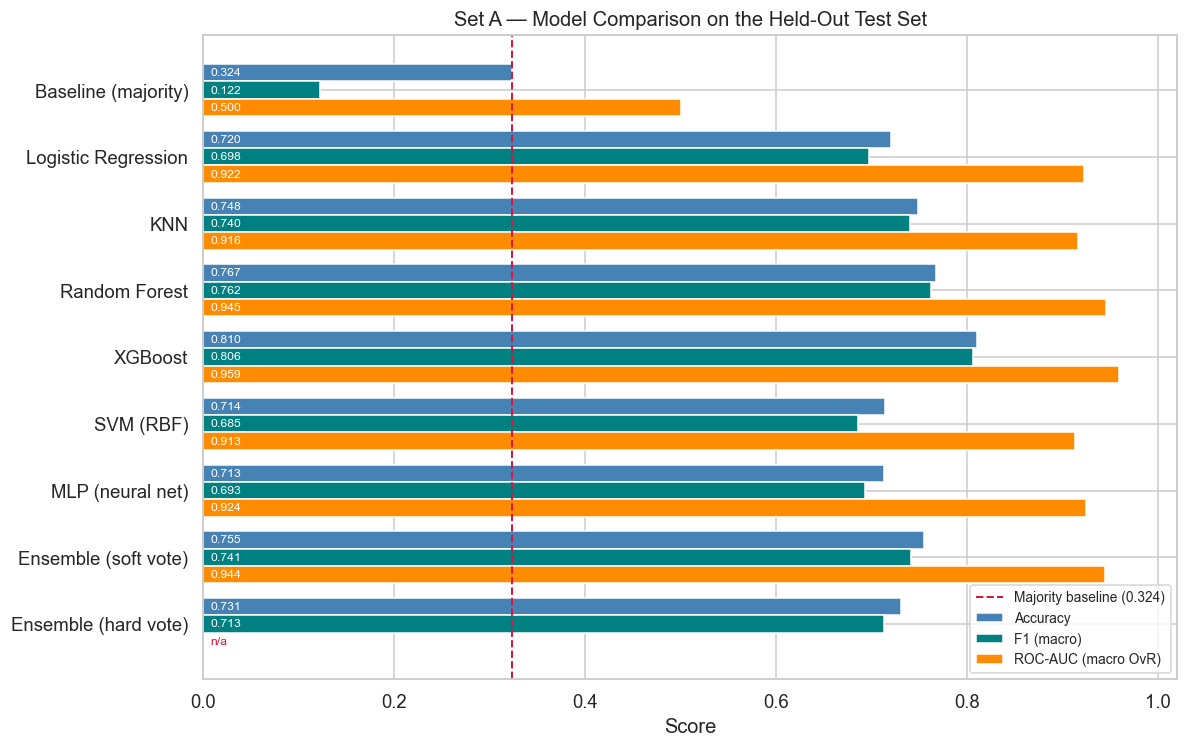

In [174]:
plot_headline_bars(res_usage, 'Set A')


**Figure 1** — Set A: accuracy, macro F1 and macro AUC for every model, with the majority
baseline marked. Hard voting has no AUC, so its bar is marked `n/a`.

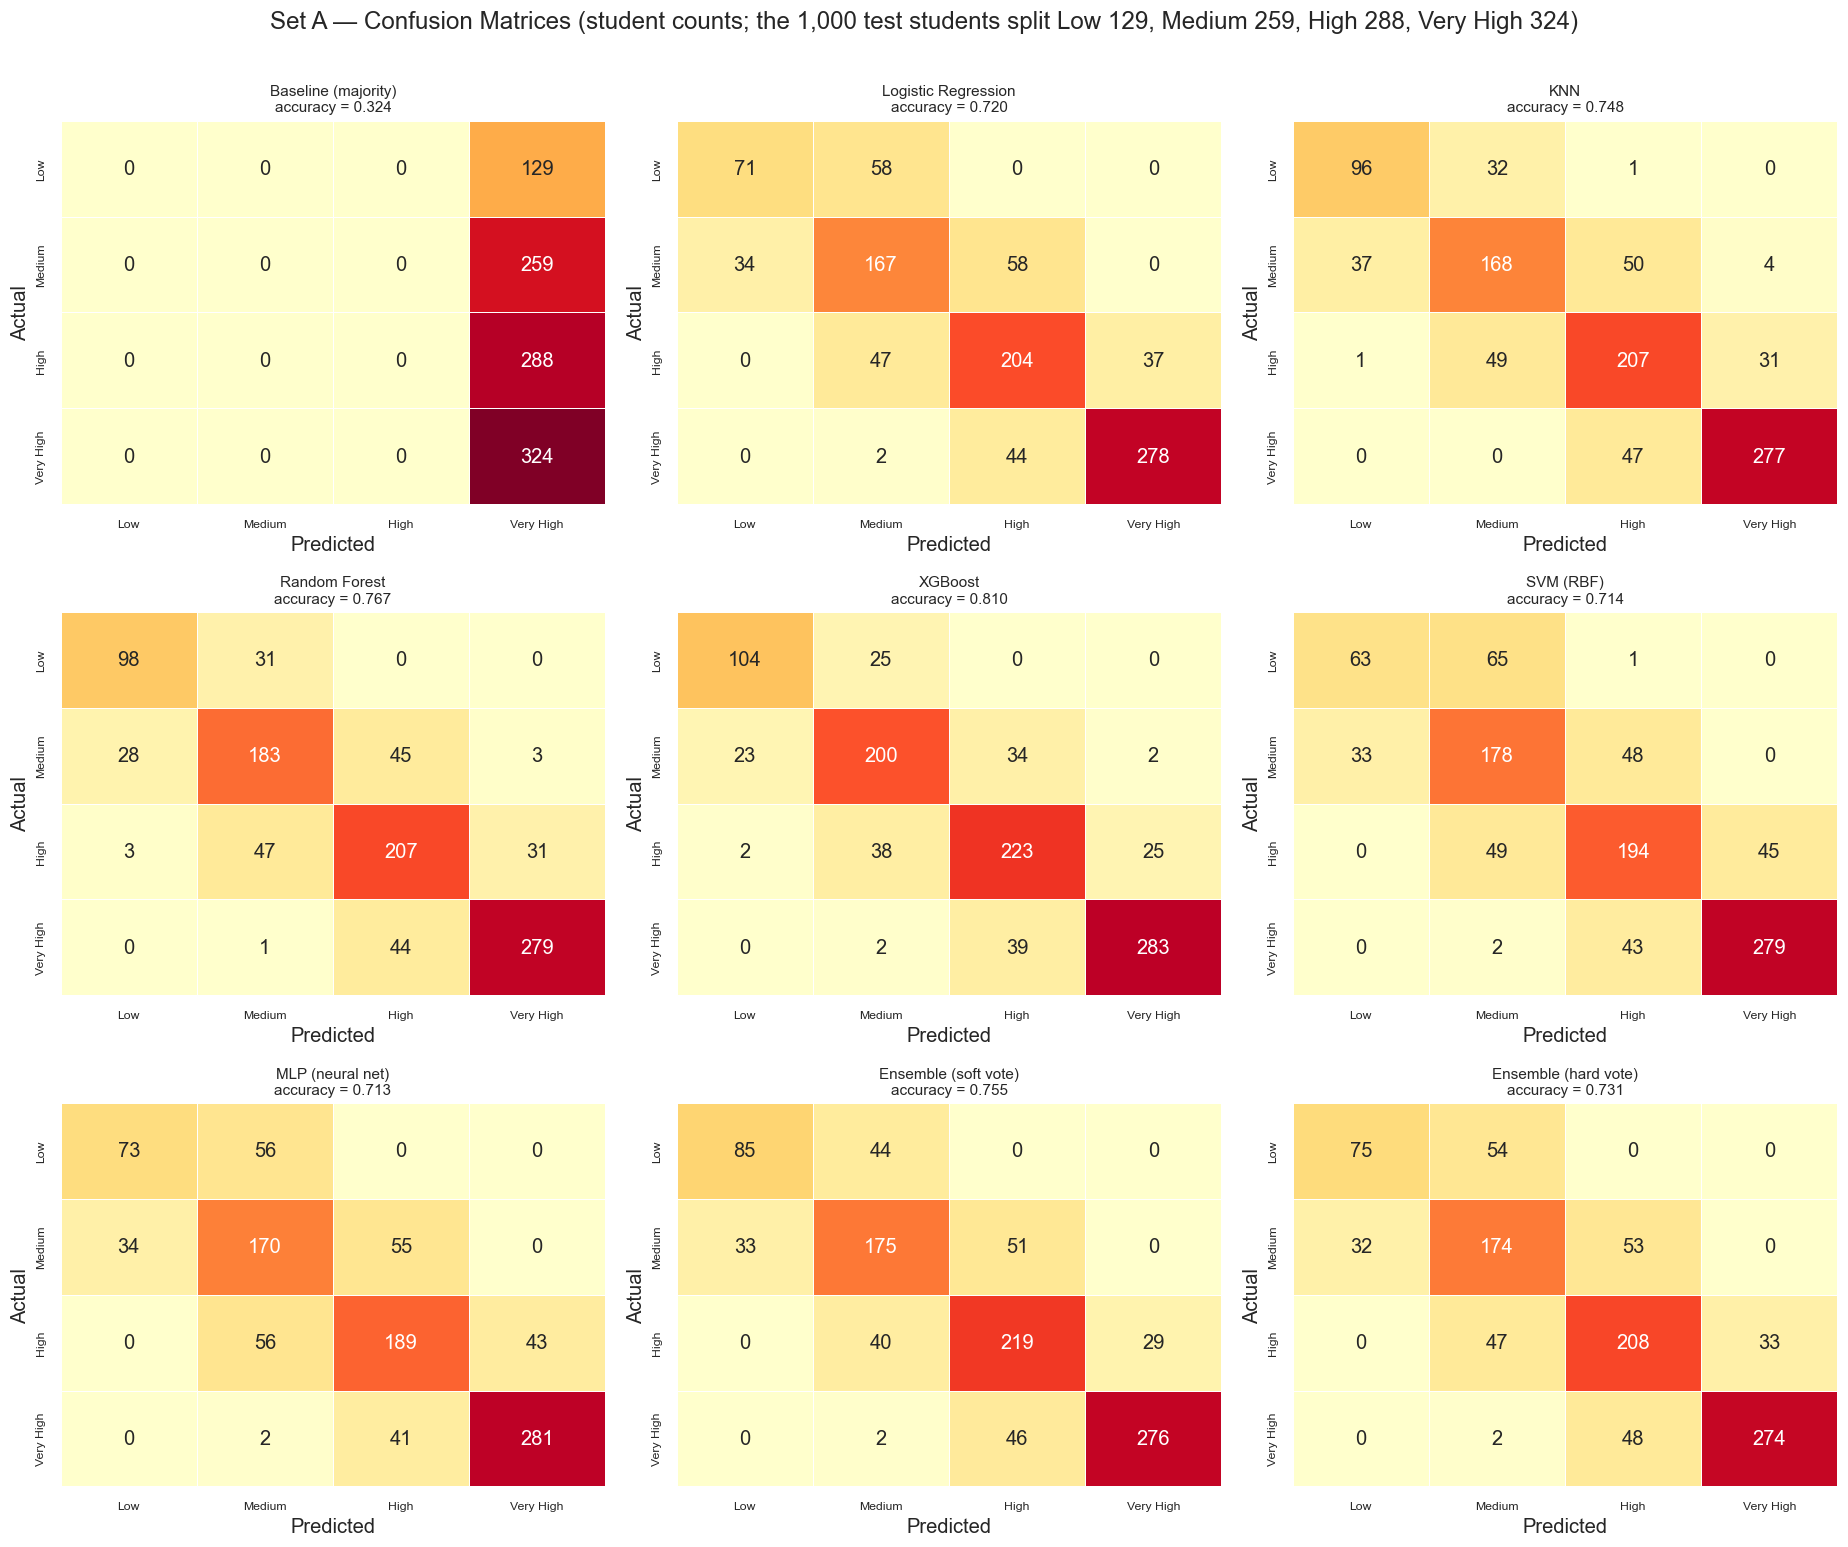

In [175]:
plot_confusions(pred_usage, res_usage, 'Set A')


**Figure 2** — Set A: confusion matrices for all 9 models, in student counts. Each row adds up
to that level's test-set size, so the diagonal is how many students the model placed correctly.

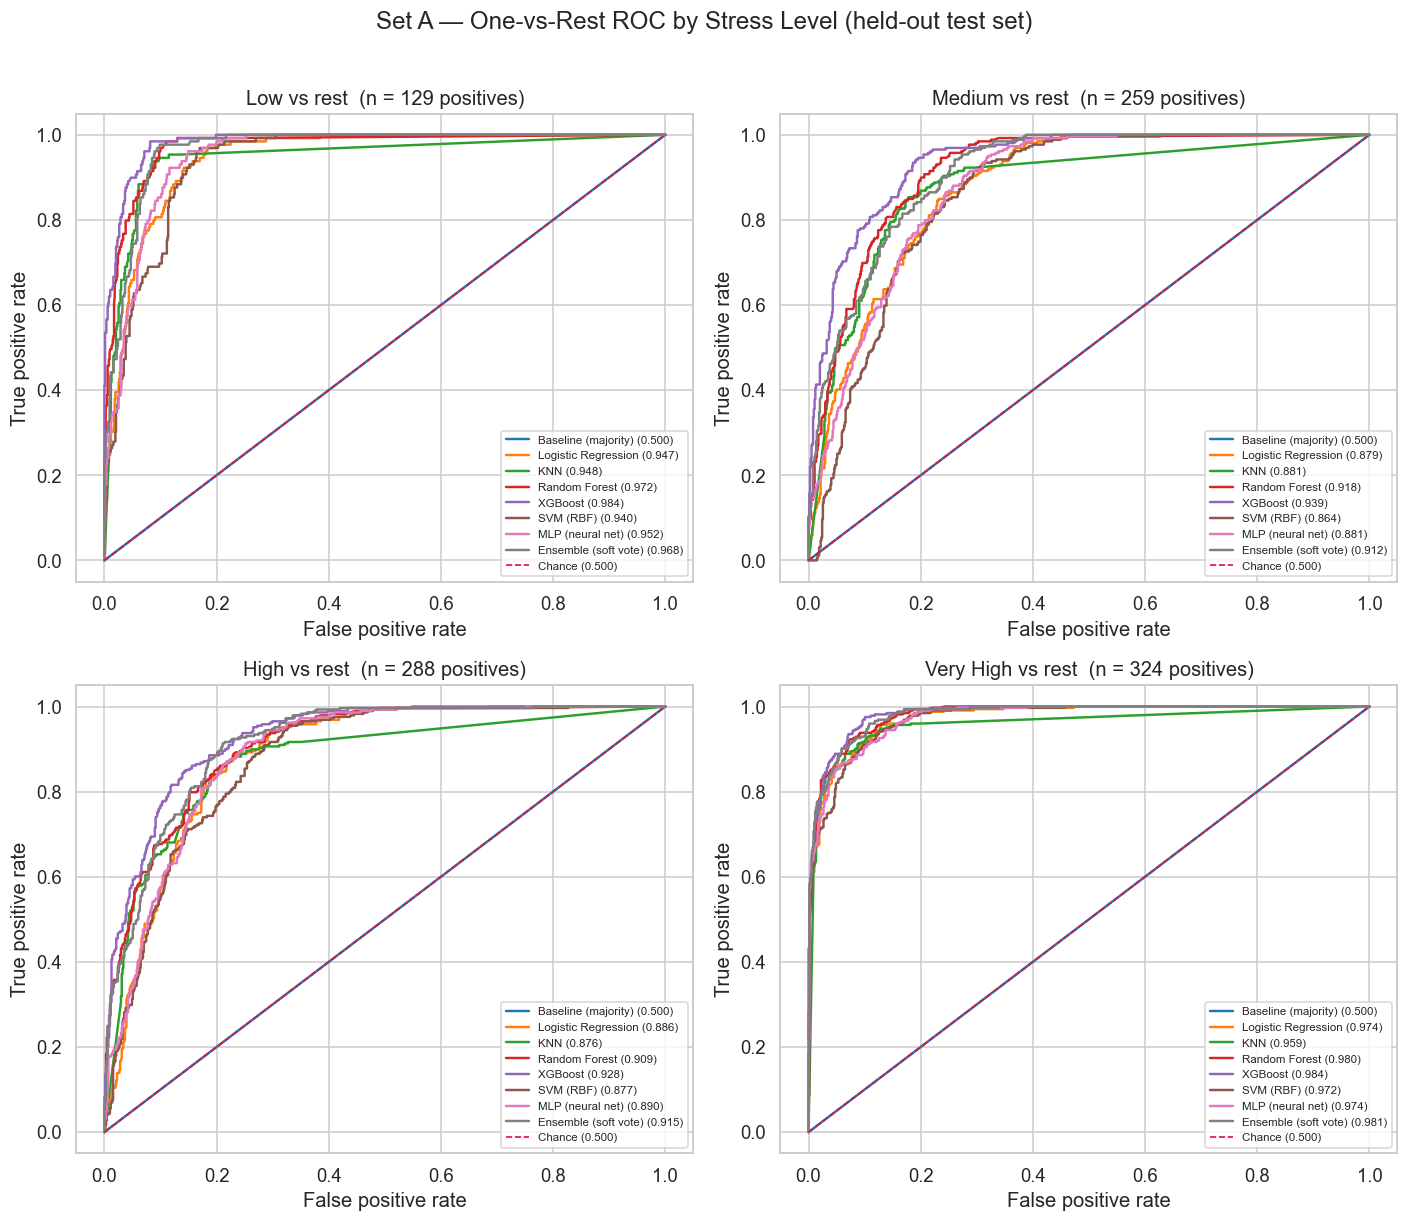

In [176]:
plot_roc_per_level(proba_usage, 'Set A')


**Figure 3** — Set A: one-vs-rest ROC per stress level, all models on top of each other.

### 3.2 Using all the features (Set B)

Our main comparison. We add sleep, study and activity hours plus age, gender and academic level, giving
23 features.

In [177]:
t0 = time.perf_counter()
res_full, pred_full, proba_full, fitted_full = run_roster(X_full, y4, 'Set B')
print(f'\nSet B total: {time.perf_counter() - t0:.1f}s')

res_full_sorted = res_full.sort_values('Accuracy', ascending=False)
print('\nSet B — all models, scored on the held-out test set '
      f'(n = {len(idx_test):,}), sorted by accuracy:')
print(res_full_sorted[show_cols].to_string(index=False))
print('\nTuning outcome and cost:')
print(res_full[['Model', 'Best params', 'Fit time (s)']].to_string(index=False))
print("\nHard voting has no predict_proba, so its AUC is '—' rather than a fabricated number "
      "(see section 3.5).")

  Set B | Baseline (majority)                           acc 0.3240  (  0.0s)  —
  Set B | Logistic Regression                           acc 0.7430  (  0.5s)  C=1, l1_ratio=0.85, penalty=elasticnet, solver=saga
  Set B | KNN                                           acc 0.9130  (  0.5s)  metric=manhattan, n_neighbors=1, weights=uniform
  Set B | Random Forest                                 acc 0.8880  (  8.4s)  max_depth=21, min_samples_leaf=1, n_estimators=200
  Set B | XGBoost                                       acc 0.8860  (  4.4s)  learning_rate=0.3, max_depth=26
  Set B | SVM (RBF)                                     acc 0.8850  (  1.6s)  C=100, gamma=0.1
  Set B | MLP (neural net)                              acc 0.8780  (  4.5s)  alpha=0.0001, hidden_layer_sizes=(128, 64)
  Set B | Ensemble (soft vote)                          acc 0.9140  (  4.6s)
  Set B | Ensemble (hard vote)                          acc 0.9060  (  4.6s)

Set B total: 29.1s

Set B — all models, scored on the

**We expected Set B to give us the same ranking as Set A, only with higher scores. That turned out to be
wrong.** Adding the lifestyle and demographic features made every model better, but not by the same
amount, and the order changed almost completely:

| Model | Set A rank | Set B rank | Accuracy gain |
|---|---|------|---|
| SVM (RBF) | 7th | 4th  | +0.171 |
| MLP (neural net) | 8th | 5th  | +0.165 |
| Ensemble (hard vote) | 5th | 2nd  | +0.160 |
| Ensemble (soft vote) | 4th | 1st  | +0.141 |
| Random Forest | 2nd | 3rd  | +0.125 |
| KNN | 3rd | 7th  | +0.107 |
| XGBoost | 1st | 6th  | +0.065 |
| Logistic Regression | 6th | 8th  | +0.024 |

Random Forest is the only model that stays roughly where it was. XGBoost falls from first to sixth, and
the SVM and the MLP — the two *worst* models on usage features alone — jump to fourth and fifth. The two
ensembles move from the middle of the table to the top.

We think the reason is the *kind* of features we added. Set A is only 2 numeric columns and 14 one-hot
dummies, which is the shape trees split on easily and which distance-based and kernel methods struggle
with. Set B adds four more smooth numeric columns — sleep, study and activity hours, and age — and those
are exactly what the SVM, the MLP and KNN were missing. Section 3.6 shows the same pattern in AUC, where
the SVM gains +0.066 and XGBoost only +0.021: the models that were being held back by the feature types
gain the most, and the model that had already extracted the most from usage alone gains the least.


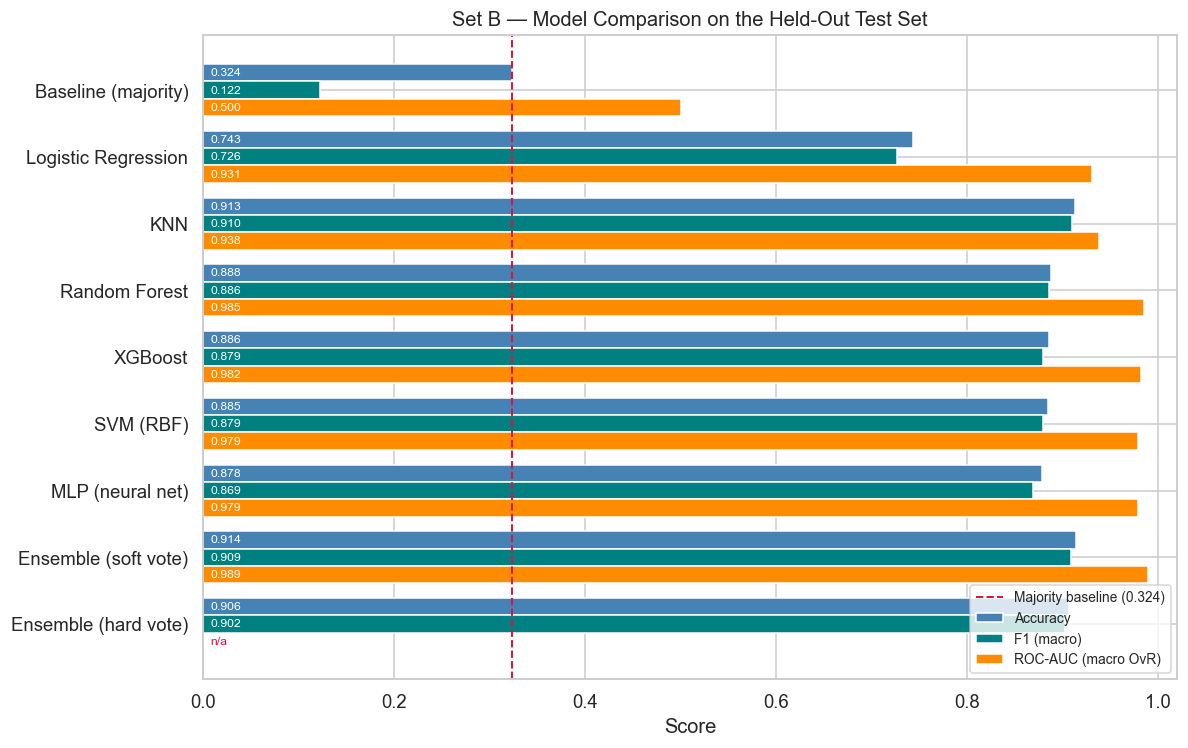

In [178]:
plot_headline_bars(res_full, 'Set B')


**Figure 4** — Set B: accuracy, macro F1 and macro AUC for every model, with the majority baseline
marked.
Hard voting has no AUC, so its bar is marked `n/a`.

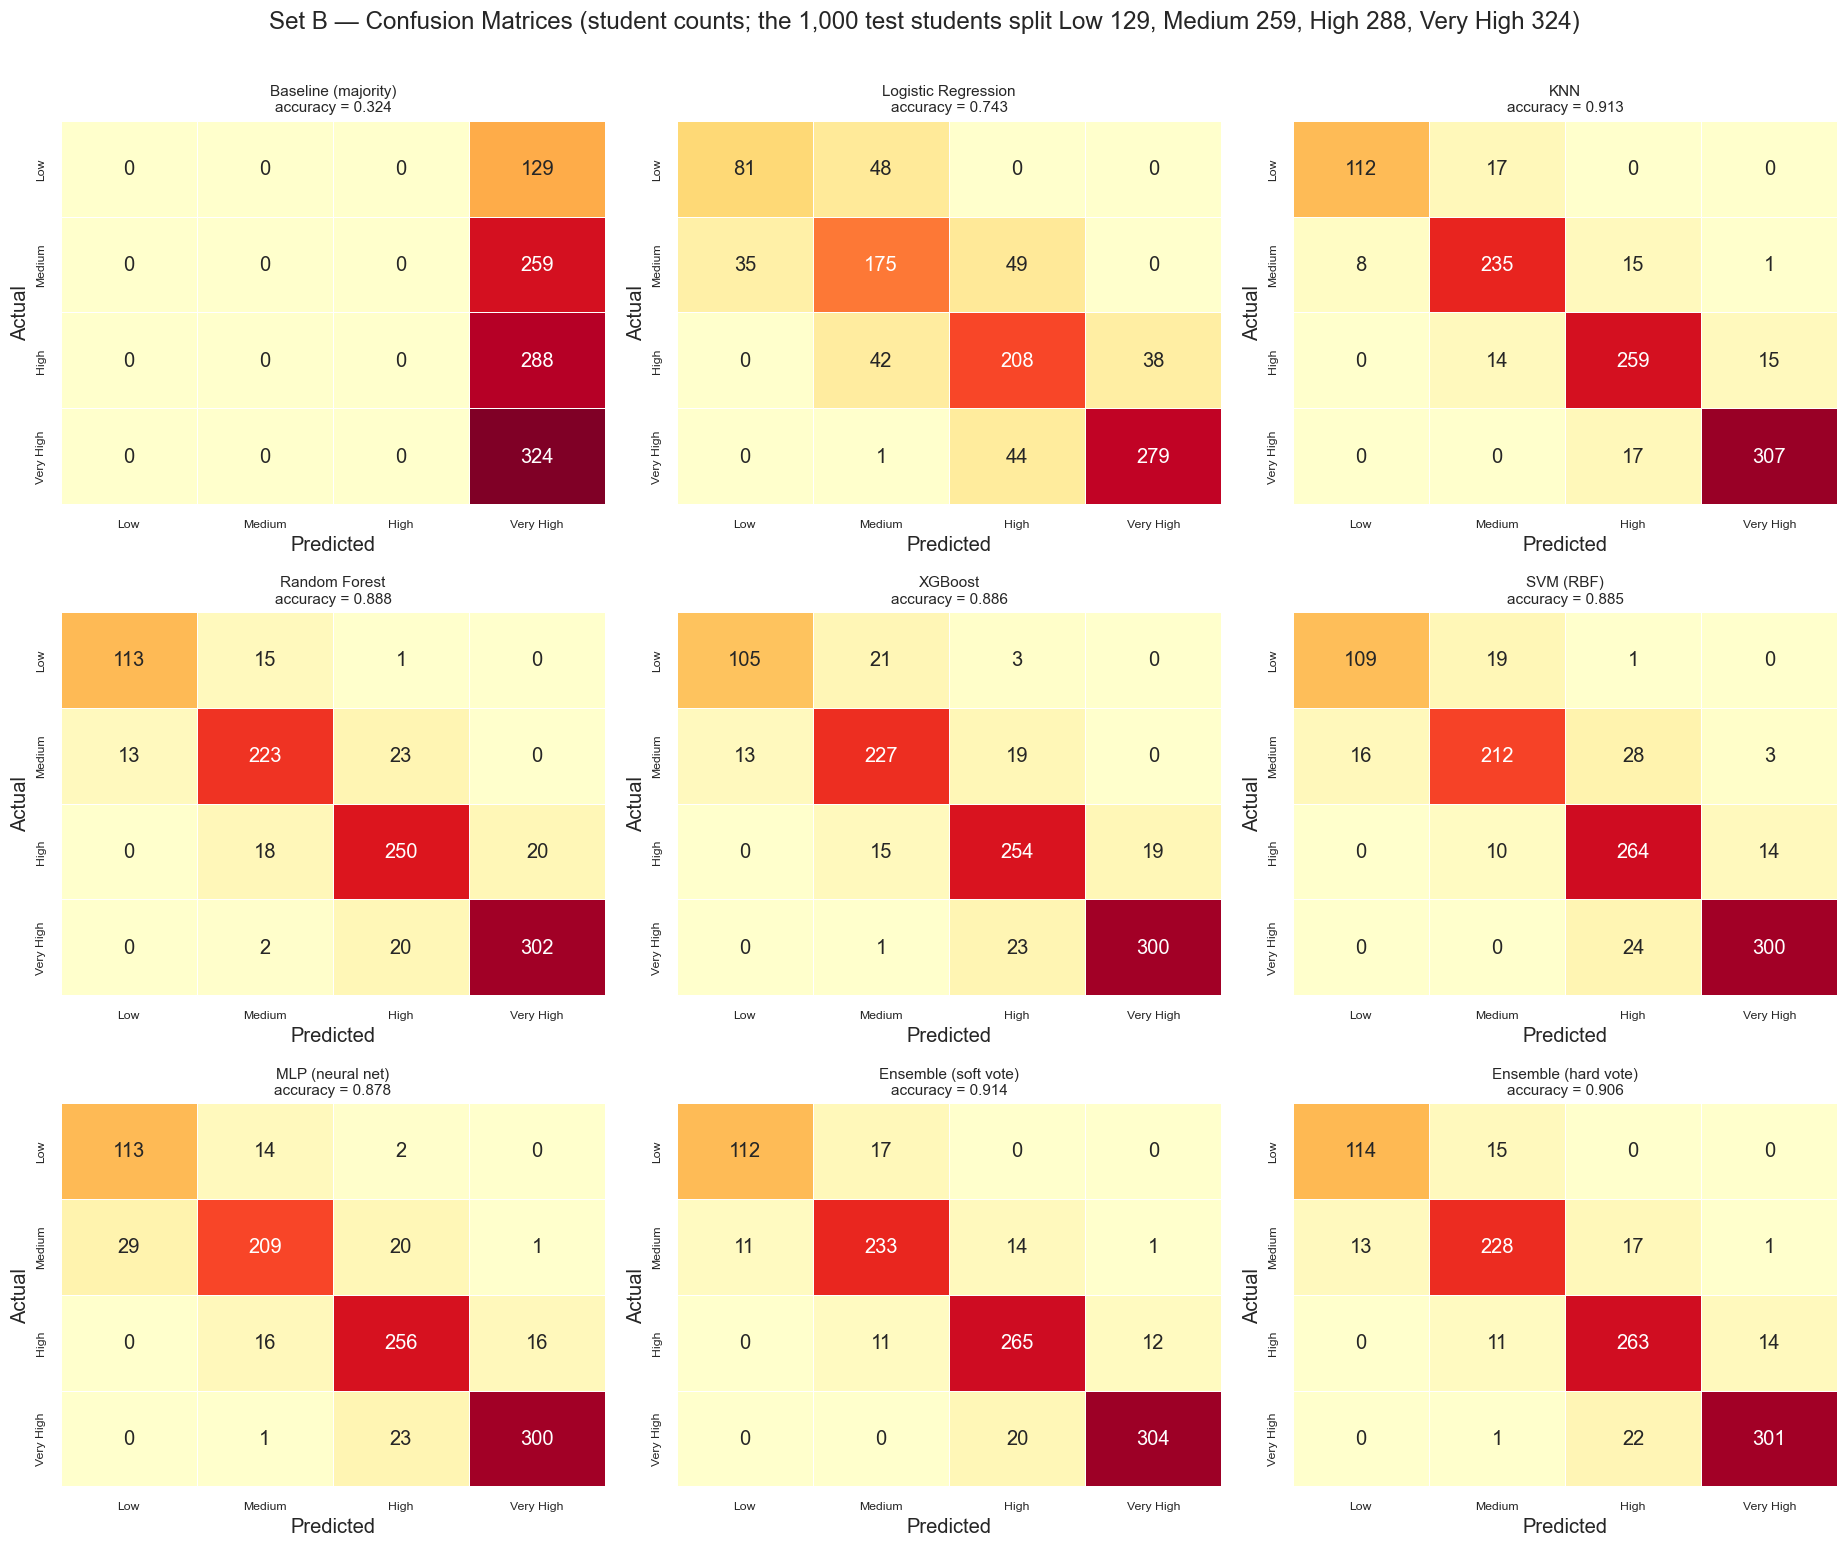

In [179]:
plot_confusions(pred_full, res_full, 'Set B')


**Figure 5** — Set B: confusion matrices for all 9 models, in student counts. Each row adds up to that level's
test-set size, so the diagonal is how many students the model placed correctly. Because the four levels
have different support, compare cells down a column with that in mind — a row with more students in it
will tend to have larger numbers everywhere.

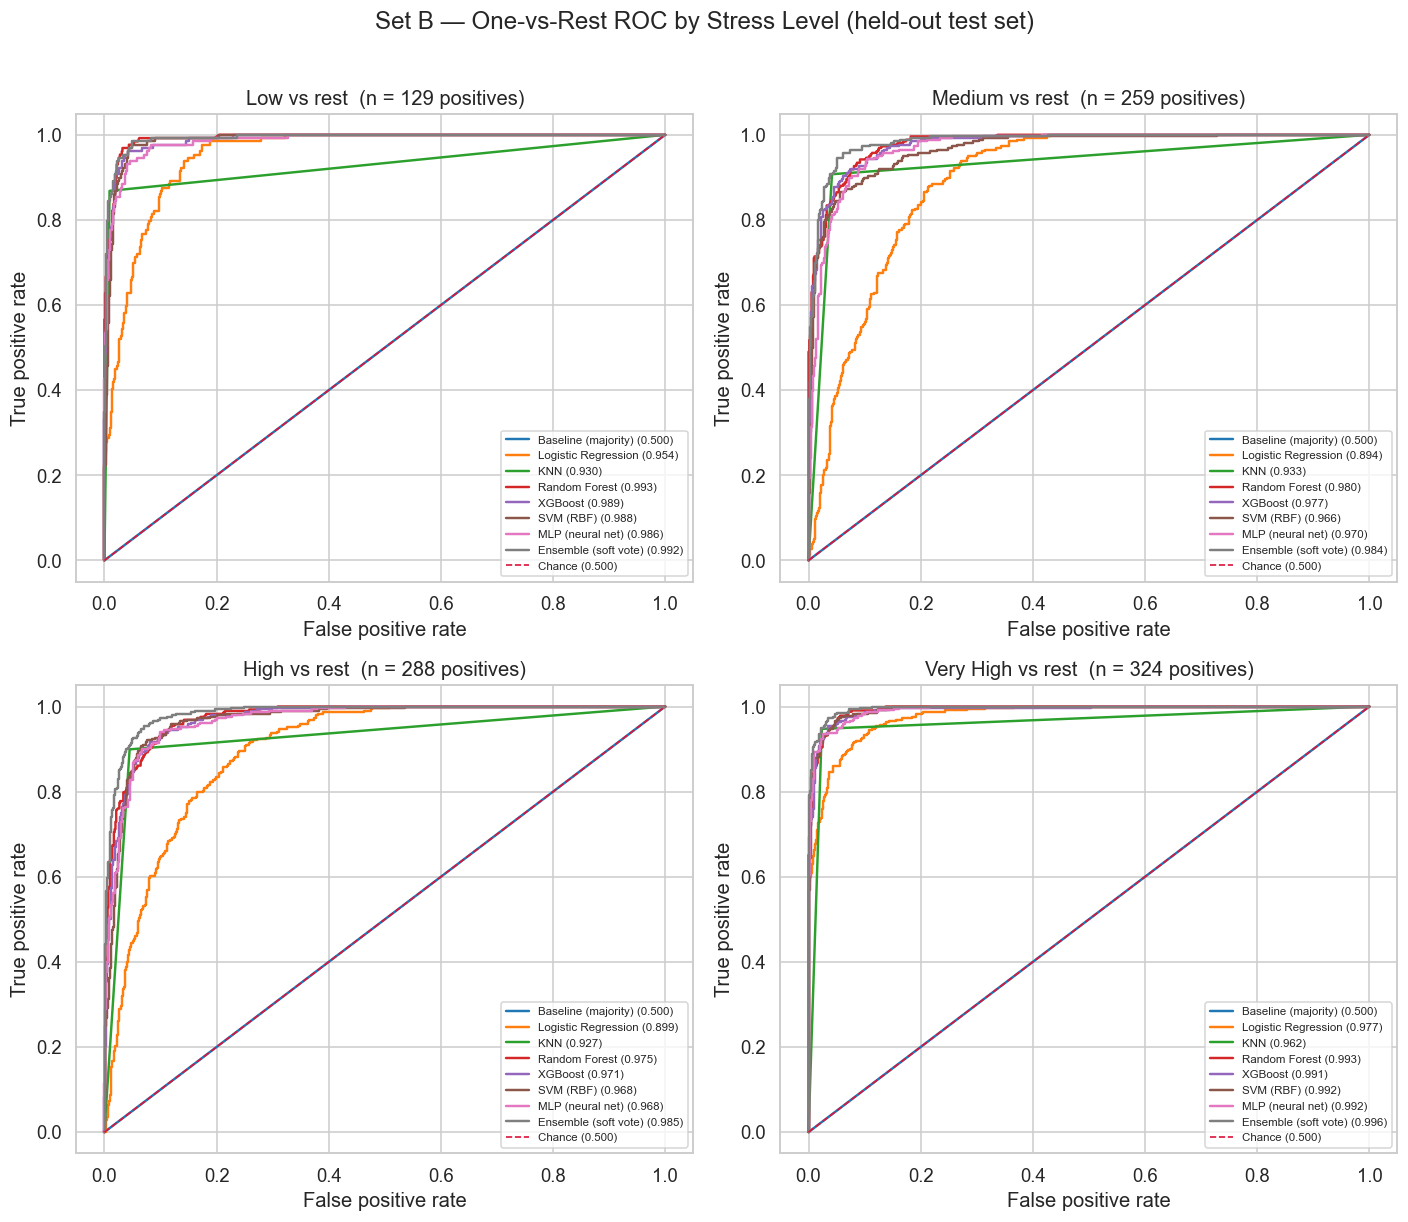

In [180]:
plot_roc_per_level(proba_full, 'Set B')


**Figure 6** — Set B: one-vs-rest ROC per stress level, all models on top of each other.

### 3.3 The winner, class by class

Our best Set B model in detail: how it does on each of the four levels separately, and how far
off its mistakes are on the ordinal scale.

Best model by macro AUC: Ensemble (soft vote)

              precision    recall  f1-score   support

         Low      0.911     0.868     0.889       129
      Medium      0.893     0.900     0.896       259
        High      0.886     0.920     0.903       288
   Very High      0.959     0.938     0.949       324

    accuracy                          0.914      1000
   macro avg      0.912     0.907     0.909      1000
weighted avg      0.915     0.914     0.914      1000



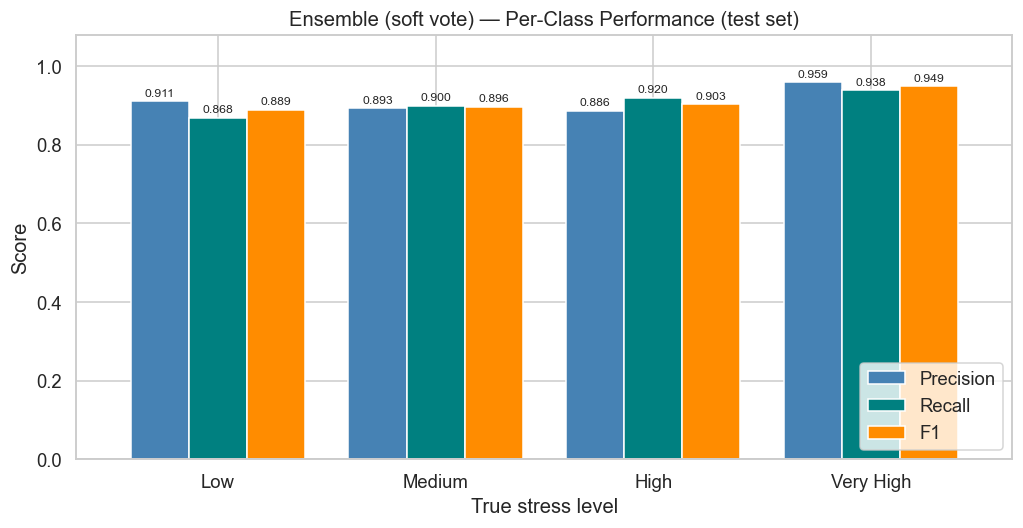

Ordinal view of the same predictions (Ensemble (soft vote)):
  Mean error in stress levels: 0.0870
  Exactly right              : 91.40%
  Within one level           : 99.90%
  Off by two or more         : 0.10%


In [181]:
# --- F5: the winner, class by class, plus the ordinal metrics ----------------
BEST_CLS = res_full_sorted['Model'].iat[0]
best_pred = pred_full[BEST_CLS]

print(f'Best model by macro AUC: {BEST_CLS}\n')
print(classification_report(y_test, best_pred, labels=range(N_CLASSES),
                            target_names=STRESS_ORDER, digits=3, zero_division=0))

p_c, r_c, f_c, sup = precision_recall_fscore_support(
    y_test, best_pred, labels=range(N_CLASSES), zero_division=0)
per_class = pd.DataFrame({'Precision': p_c, 'Recall': r_c, 'F1': f_c}, index=STRESS_ORDER)

fig, ax = plt.subplots(figsize=(9.5, 5))
per_class.plot(kind='bar', ax=ax, color=['steelblue', 'teal', 'darkorange'], edgecolor='white',
               rot=0, width=0.8)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=8, padding=2)
ax.set_ylim(0, 1.08); ax.set_ylabel('Score'); ax.set_xlabel('True stress level')
ax.set_title(f'{BEST_CLS} — Per-Class Performance (test set)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

# The target is ORDERED, and a plain classification report ignores that: it treats
# Low-mistaken-for-Very-High exactly like Medium-mistaken-for-High.
ordinal_err = np.abs(best_pred - y_test)
print(f'Ordinal view of the same predictions ({BEST_CLS}):')
print(f'  Mean error in stress levels: {ordinal_err.mean():.4f}')
print(f'  Exactly right              : {(ordinal_err == 0).mean():.2%}')
print(f'  Within one level           : {(ordinal_err <= 1).mean():.2%}')
print(f'  Off by two or more         : {(ordinal_err >= 2).mean():.2%}')

**Figure 7** — precision, recall and F1 for each stress level, for our best model.


### 3.4 Ensemble learning: soft voting vs hard voting

Both ensembles use the **same five tuned models** (logistic regression, KNN, random forest, SVM, MLP), so
the only difference is how we combine them:

- **Hard voting** counts votes. Each member picks one class and the majority wins. A member that is 51%
  sure counts the same as one that is 99% sure.
- **Soft voting** averages the probabilities. Confidence matters, so one very sure member can outvote
  several members that are only leaning.

We expected soft voting to win, since the confidence it uses is real information. But soft voting can fail if a badly calibrated member
is confidently wrong, where hard voting would just outvote it. We did not want to guess which effect is
stronger, so we measured it.

In [182]:
soft_pred, hard_pred = pred_full['Ensemble (soft vote)'], pred_full['Ensemble (hard vote)']

vote_cmp = res_full.set_index('Model').loc[
    ['Ensemble (soft vote)', 'Ensemble (hard vote)'],
    ['Accuracy', 'Balanced Acc', 'Precision (macro)', 'Recall (macro)',
     'F1 (macro)', 'F1 (weighted)', 'ROC-AUC (macro OvR)']]
print('Soft versus hard voting — identical members, different combination rule:')
print(vote_cmp.to_string())

agree = (soft_pred == hard_pred).mean()
print(f'\nThe two rules agree on {agree:.2%} of the {len(y_test):,} test students '
      f'({int((soft_pred != hard_pred).sum())} disagreements).')

# On the students where they disagree, which rule is right?
dis = soft_pred != hard_pred
if dis.any():
    print(f'  On those {int(dis.sum())} students: '
          f'soft correct {int((soft_pred[dis] == y_test[dis]).sum())}, '
          f'hard correct {int((hard_pred[dis] == y_test[dis]).sum())}, '
          f'both wrong {int(((soft_pred[dis] != y_test[dis]) & (hard_pred[dis] != y_test[dis])).sum())}')

# How many students separate the two rules, in plain counts.
gap = accuracy_score(y_test, soft_pred) - accuracy_score(y_test, hard_pred)
print(f'\nAccuracy gap (soft − hard): {gap:+.4f} = {abs(round(gap * len(y_test)))} student(s) '
      f'out of {len(y_test):,}.')

Soft versus hard voting — identical members, different combination rule:
                      Accuracy  Balanced Acc  Precision (macro)  Recall (macro)  F1 (macro)  F1 (weighted)  ROC-AUC (macro OvR)
Model                                                                                                                          
Ensemble (soft vote)     0.914        0.9066             0.9121          0.9066      0.9091         0.9141               0.9893
Ensemble (hard vote)     0.906        0.9016             0.9038          0.9016      0.9025         0.9062                  NaN

The two rules agree on 96.60% of the 1,000 test students (34 disagreements).
  On those 34 students: soft correct 21, hard correct 13, both wrong 0

Accuracy gap (soft − hard): +0.0080 = 8 student(s) out of 1,000.


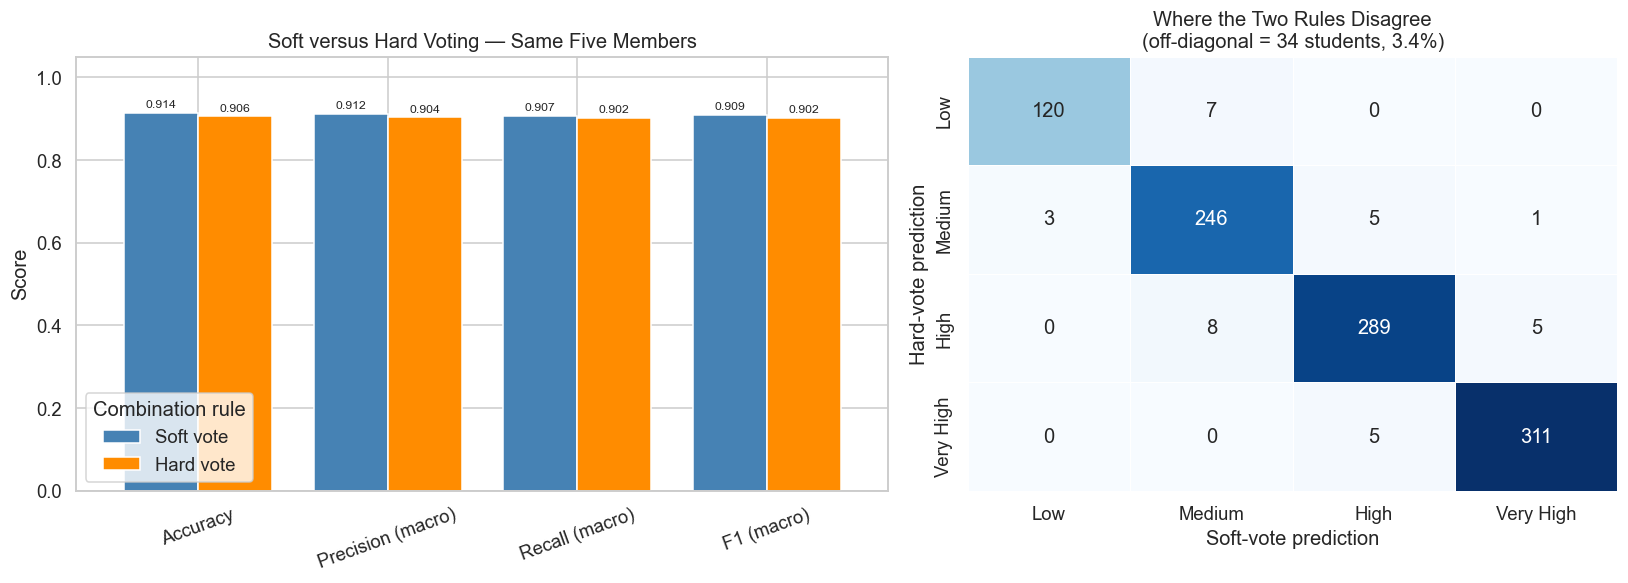

In [183]:
# --- F7: soft vs hard, metrics side by side and where they disagree ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5),
                         gridspec_kw={'width_ratios': [1.25, 1]})

m_cols = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']
bar = vote_cmp[m_cols].T
bar.columns = ['Soft vote', 'Hard vote']
bar.plot(kind='bar', ax=axes[0], color=['steelblue', 'darkorange'], edgecolor='white',
         rot=20, width=0.78)
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt='%.3f', fontsize=8, padding=2)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel('Score')
axes[0].set_title('Soft versus Hard Voting — Same Five Members')
axes[0].legend(title='Combination rule')

xt = confusion_matrix(hard_pred, soft_pred, labels=range(N_CLASSES))
sns.heatmap(xt, ax=axes[1], annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=STRESS_ORDER, yticklabels=STRESS_ORDER,
            linewidths=0.5, linecolor='white')
axes[1].set_xlabel('Soft-vote prediction'); axes[1].set_ylabel('Hard-vote prediction')
axes[1].set_title(f'Where the Two Rules Disagree\n(off-diagonal = {int(dis.sum())} students, '
                  f'{1 - agree:.1%})')
plt.tight_layout(); plt.show()

**Figure 8** — left: the two combination rules side by side. Right: where they disagree (off-diagonal
cells).

As we expected we can see that soft voting dominate hard voting in every class, but this is minor domination as we can see in the bar chart.
We can also see on the confusion matrix that the two models are disagree in very little number of students.

### 3.5 What the extra features add, and whether we were right to drop `Country`

Two questions here. First, how much does each model gain from the lifestyle and demographic features?
We measure that gain on **test accuracy** rather than on macro AUC, for two reasons: accuracy is the
headline number we report everywhere else in this section, and it is the one measure every model has —
hard voting produces labels without probabilities, so an AUC comparison silently drops it from the
figure. The trade-off is that accuracy depends on where each model puts its decision boundaries, while
AUC only measures ranking, so a model can improve its ranking without moving its accuracy at all.
Second, we left `Country` out in  section 2.4, and we should check that decision instead of just asserting it. With
111 countries and most of them having under 20 students, we expected country dummies to raise validation
accuracy and then fail on the test set — and a held-out test set is exactly the tool that can tell us.

**Figure 9** — change in test accuracy from Set A to Set B, per model.

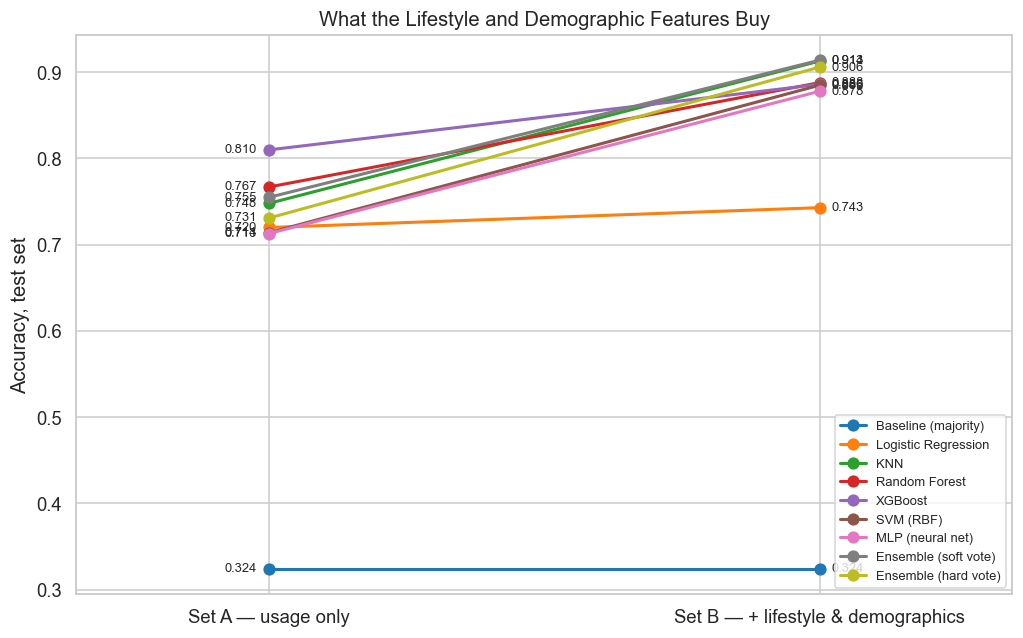

Test accuracy by feature set:
                      Set A — usage only  Set B — + lifestyle & demographics   Gain
Model                                                                              
Baseline (majority)                0.324                               0.324  0.000
Logistic Regression                0.720                               0.743  0.023
KNN                                0.748                               0.913  0.165
Random Forest                      0.767                               0.888  0.121
XGBoost                            0.810                               0.886  0.076
SVM (RBF)                          0.714                               0.885  0.171
MLP (neural net)                   0.713                               0.878  0.165
Ensemble (soft vote)               0.755                               0.914  0.159
Ensemble (hard vote)               0.731                               0.906  0.175

Ranked by gain (students out of 1,000 who mov

In [184]:
# --- F6: what the extra features buy, per model ------------------------------
# Accuracy rather than AUC, so hard voting is in the comparison: it predicts labels
# with no probabilities behind them, so it has an accuracy but no ROC curve.
cmp_acc = pd.DataFrame({
    'Set A — usage only': res_usage.set_index('Model')['Accuracy'],
    'Set B — + lifestyle & demographics': res_full.set_index('Model')['Accuracy'],
}).loc[MODEL_ORDER].dropna()

fig, ax = plt.subplots(figsize=(9.5, 6))
for m, row in cmp_acc.iterrows():
    ax.plot([0, 1], row.to_numpy(), '-o', color=MODEL_COLORS[m], lw=2, ms=7, label=m)
    ax.annotate(f'{row.iloc[1]:.3f}', (1, row.iloc[1]), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=8.5)
    ax.annotate(f'{row.iloc[0]:.3f}', (0, row.iloc[0]), xytext=(-8, 0),
                textcoords='offset points', va='center', ha='right', fontsize=8.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(cmp_acc.columns)
ax.set_xlim(-0.35, 1.35); ax.set_ylabel('Accuracy, test set')
ax.set_title('What the Lifestyle and Demographic Features Buy')
ax.legend(fontsize=8.5, loc='lower right')
plt.tight_layout(); plt.show()

gain = (cmp_acc.iloc[:, 1] - cmp_acc.iloc[:, 0]).round(4)
print('Test accuracy by feature set:')
print(cmp_acc.assign(**{'Gain': gain}).round(4).to_string())
print('\nRanked by gain (students out of 1,000 who move to the right level):')
for m, g in gain.drop('Baseline (majority)', errors='ignore').sort_values(ascending=False).items():
    print(f'  {m:<22} {g:+.4f}   ({int(round(g * len(idx_test))):+d} students)')


The extra features help every model, and they help the smooth models most. Gains in test accuracy:
hard vote +0.175, SVM +0.171, KNN +0.165, MLP +0.165, soft vote +0.159, Random Forest +0.121, XGBoost
+0.076, Logistic Regression +0.023. On a 1,000-student test set those are 175 and 23 students
respectively, so the spread between the models is far wider than anything we saw inside Set B.

The order makes sense to us. XGBoost gains least of the non-linear models because it had already got the
most out of usage alone — it is the best model on Set A (0.810) and only fifth on Set B (0.886). The
kernel, distance and neural models gain most, since sleep, study and activity hours are smooth and
roughly monotone, which is what those models are good at. KNN in particular goes from 0.748 to 0.913 and
ends up second overall. Logistic regression gains least of all (+0.023), which confirms what we said in
3.2: its limit is the straight line, not the features we give it.

In [185]:
# --- Country sensitivity check: validation gain vs test gain -----------------
TOP_N_COUNTRIES = 20
top_countries = (df['Country'].iloc[idx_train]
                 .value_counts().nlargest(TOP_N_COUNTRIES).index.tolist())
df['Country_Grouped'] = df['Country'].where(df['Country'].isin(top_countries), 'Other')
X_country = build_X(FULL_NUM, FULL_CAT, extra_cat=['Country_Grouped'])

print(f'Set B + Country: {X_full.shape[1]} -> {X_country.shape[1]} columns '
      f'(+{X_country.shape[1] - X_full.shape[1]} country dummies)\n')

def estimator_for(label):
    """Rebuild any roster model by name, ensembles included, as an unfitted (estimator, grid)."""
    for n, e, g in BASE_MODELS:
        if n == label:
            return clone(e), g
    voting = 'soft' if 'soft' in label else 'hard'
    members = [(k.split()[0].lower(), clone(fitted_full[k])) for k in VOTE_MEMBER_KEYS]
    return VotingClassifier(members, voting=voting, n_jobs=-1), {}


country_rows = []
for label in dict.fromkeys(['Random Forest', BEST_CLS]):   # de-duplicated, order preserved
    est, grid = estimator_for(label)
    for set_name, X in [('Set B (no country)', X_full), ('Set B + country', X_country)]:
        search = GridSearchCV(make_pipe(clone(est)), grid, cv=VAL_SPLIT,
                              scoring='accuracy', n_jobs=-1, refit=True)
        search.fit(X.iloc[idx_fit], y4[idx_fit])
        country_rows.append({
            'Model': label, 'Feature set': set_name,
            'Validation accuracy': round(search.best_score_, 4),
            'Test accuracy': round(search.best_estimator_.score(X.iloc[idx_test], y_test), 4),
        })

country_df = pd.DataFrame(country_rows)
print('Does adding 20 country dummies actually help?')
print(country_df.to_string(index=False))
print('\nGain from adding country:')
for m, g in country_df.groupby('Model', sort=False):
    print(f'  {m:<22} validation {g["Validation accuracy"].iat[1] - g["Validation accuracy"].iat[0]:+.4f}'
          f'   test {g["Test accuracy"].iat[1] - g["Test accuracy"].iat[0]:+.4f}')

Set B + Country: 23 -> 42 columns (+19 country dummies)

Does adding 20 country dummies actually help?
               Model        Feature set  Validation accuracy  Test accuracy
       Random Forest Set B (no country)                0.849          0.888
       Random Forest    Set B + country                0.860          0.904
Ensemble (soft vote) Set B (no country)                0.876          0.914
Ensemble (soft vote)    Set B + country                0.885          0.936

Gain from adding country:
  Random Forest          validation +0.0110   test +0.0160
  Ensemble (soft vote)   validation +0.0090   test +0.0220


#### 3.5.1 Our country test did not come out the way we expected

We built this test to show overfitting. Instead, the gain **held up on the test set**: Random Forest
+0.0110 on validation and **+0.0160 on test**; soft vote +0.0090 on validation and **+0.0220 on test**.
For both models it was larger on the test set than on validation, roughly twice as large for the
ensemble. So country really does carry useful information here, and our overfitting explanation was
wrong.

We still keep Set B as our main feature set, but for a different reason than we originally gave. Our
question is about *usage characteristics*, and a model that leans on which of 111 countries a student is
from is answering something else — with under 20 students per country it is describing our sample rather
than anything that would transfer to new students. That is a reasonable choice, but it is a choice about
our research question and not about accuracy: on accuracy alone, adding country is worth 1.6% to 2.2%
accuracy. We list this in our limitations instead of pretending it was noise.

### 3.6 Predicting the mental-health score

The second half of our question. This target is continuous, so accuracy and AUROC do not apply and we use
the matching measures instead:

| Measure | What it means |
|---|---|
| R² | how much of the variance we explain (1 = perfect, 0 = no better than always guessing the mean) |
| MSE | mean squared error — what the models actually minimise |
| RMSE | root mean squared error, back on the 3.6–9.4 scale of the score |
| MAE | mean absolute error — how far off we usually are, in score points |

Same students, same splits, same protocol as before. Only the target and the metrics change, and we tune
on MSE instead of accuracy.

In [186]:
# The five regressors named in the research proposal, plus a mean baseline. The proposal's
# regression list does not include a boosting model, so there is no XGBoost row here.
REG_MODELS = [
    ('Baseline (mean)', DummyRegressor(strategy='mean'), {}),
    # Ordinary least squares has no regularisation strength, kernel or depth to set, so
    # there is genuinely nothing to search. Tuning it would need a different estimator
    # (Ridge / Lasso / ElasticNet), which is not the model our proposal named.
    ('Linear Regression', LinearRegression(), {}),
    ('Random Forest Regressor', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {'model__n_estimators': range(100, 501, 100),
         'model__max_depth': [None] + list(range(1, 30, 5)),
         'model__min_samples_leaf': range(1, 11, 2)}),
    ('KNN Regressor', KNeighborsRegressor(n_jobs=-1),
        {'model__n_neighbors': range(1, 31), 'model__weights': ['uniform', 'distance'],
         'model__metric': ['euclidean', 'manhattan', 'chebyshev']}),
    # epsilon is the one knob with no classifier counterpart: it sets the width of the
    # tube around the regression line inside which errors cost nothing.
    ('SVR (RBF)', SVR(cache_size=1000),
        {'model__C': [1, 10, 100], 'model__gamma': ['scale', 0.1],
         'model__epsilon': [0.01, 0.1, 0.5]}),
    ('MLP Regressor (neural net)', MLPRegressor(max_iter=1000, random_state=RANDOM_STATE),
        {'model__hidden_layer_sizes': [(64, 32), (128, 64)], 'model__alpha': [1e-4, 1e-2]}),
]

reg_roster = pd.DataFrame([
    dict(zip(['Model', 'Tuned parameters', 'Grid points'], (n, *grid_summary(g))))
    for n, _, g in REG_MODELS
])
print('Regression roster:')
print(reg_roster.to_string(index=False), '\n')

y_reg_test = y_reg[idx_test]
reg_rows, reg_preds, reg_fitted = [], {}, {}
t0 = time.perf_counter()
for label, est, grid in REG_MODELS:
    t1 = time.perf_counter()
    search = GridSearchCV(make_pipe(clone(est)), grid, cv=VAL_SPLIT,
                          scoring='neg_mean_squared_error', n_jobs=-1, refit=True)
    search.fit(X_full.iloc[idx_fit], y_reg[idx_fit])
    pred = search.best_estimator_.predict(X_full.iloc[idx_test])
    reg_preds[label] = pred
    reg_fitted[label] = search.best_estimator_
    mse = mean_squared_error(y_reg_test, pred)
    reg_rows.append({
        'Model': label,
        'R²': round(r2_score(y_reg_test, pred), 4),
        'MSE': round(mse, 4),
        'RMSE': round(np.sqrt(mse), 4),
        'MAE': round(mean_absolute_error(y_reg_test, pred), 4),
        'Best params': (', '.join(f'{k.replace("model__", "")}={v}'
                                  for k, v in search.best_params_.items()) or '—'),
        'Fit time (s)': round(time.perf_counter() - t1, 1),
    })
    print(f'  {label:<28} R² {reg_rows[-1]["R²"]:.4f}  RMSE {reg_rows[-1]["RMSE"]:.4f}  '
          f'({reg_rows[-1]["Fit time (s)"]:>5.1f}s)')

res_reg = pd.DataFrame(reg_rows).sort_values('R²', ascending=False)
print(f'\nRegression total: {time.perf_counter() - t0:.1f}s')
print(f'\nPredicting {MHS_COL} on the held-out test set (n = {len(idx_test):,}), sorted by R²:')
print(res_reg.to_string(index=False))
print(f'\nFor scale: the test-set SD of {MHS_COL} is {y_reg_test.std():.4f}, so an RMSE below that '
      'means the model beats always guessing the mean.')

Regression roster:
                     Model                          Tuned parameters  Grid points
           Baseline (mean)                                         —            1
         Linear Regression                                         —            1
   Random Forest Regressor n_estimators, max_depth, min_samples_leaf          175
             KNN Regressor              n_neighbors, weights, metric          180
                 SVR (RBF)                         C, gamma, epsilon           18
MLP Regressor (neural net)                 hidden_layer_sizes, alpha            4 

  Baseline (mean)              R² -0.0004  RMSE 1.2870  (  0.0s)
  Linear Regression            R² 0.7023  RMSE 0.7022  (  0.0s)
  Random Forest Regressor      R² 0.8540  RMSE 0.4917  ( 18.0s)
  KNN Regressor                R² 0.8892  RMSE 0.4284  (  0.5s)
  SVR (RBF)                    R² 0.8251  RMSE 0.5381  (  2.1s)
  MLP Regressor (neural net)   R² 0.8495  RMSE 0.4992  (  3.8s)

Regression total: 2

**Figure 10** — predicted vs actual score for each regressor; the dashed line is a perfect prediction.

**Figure 11** — R² and RMSE per model, with the mean baseline and the outcome SD marked.

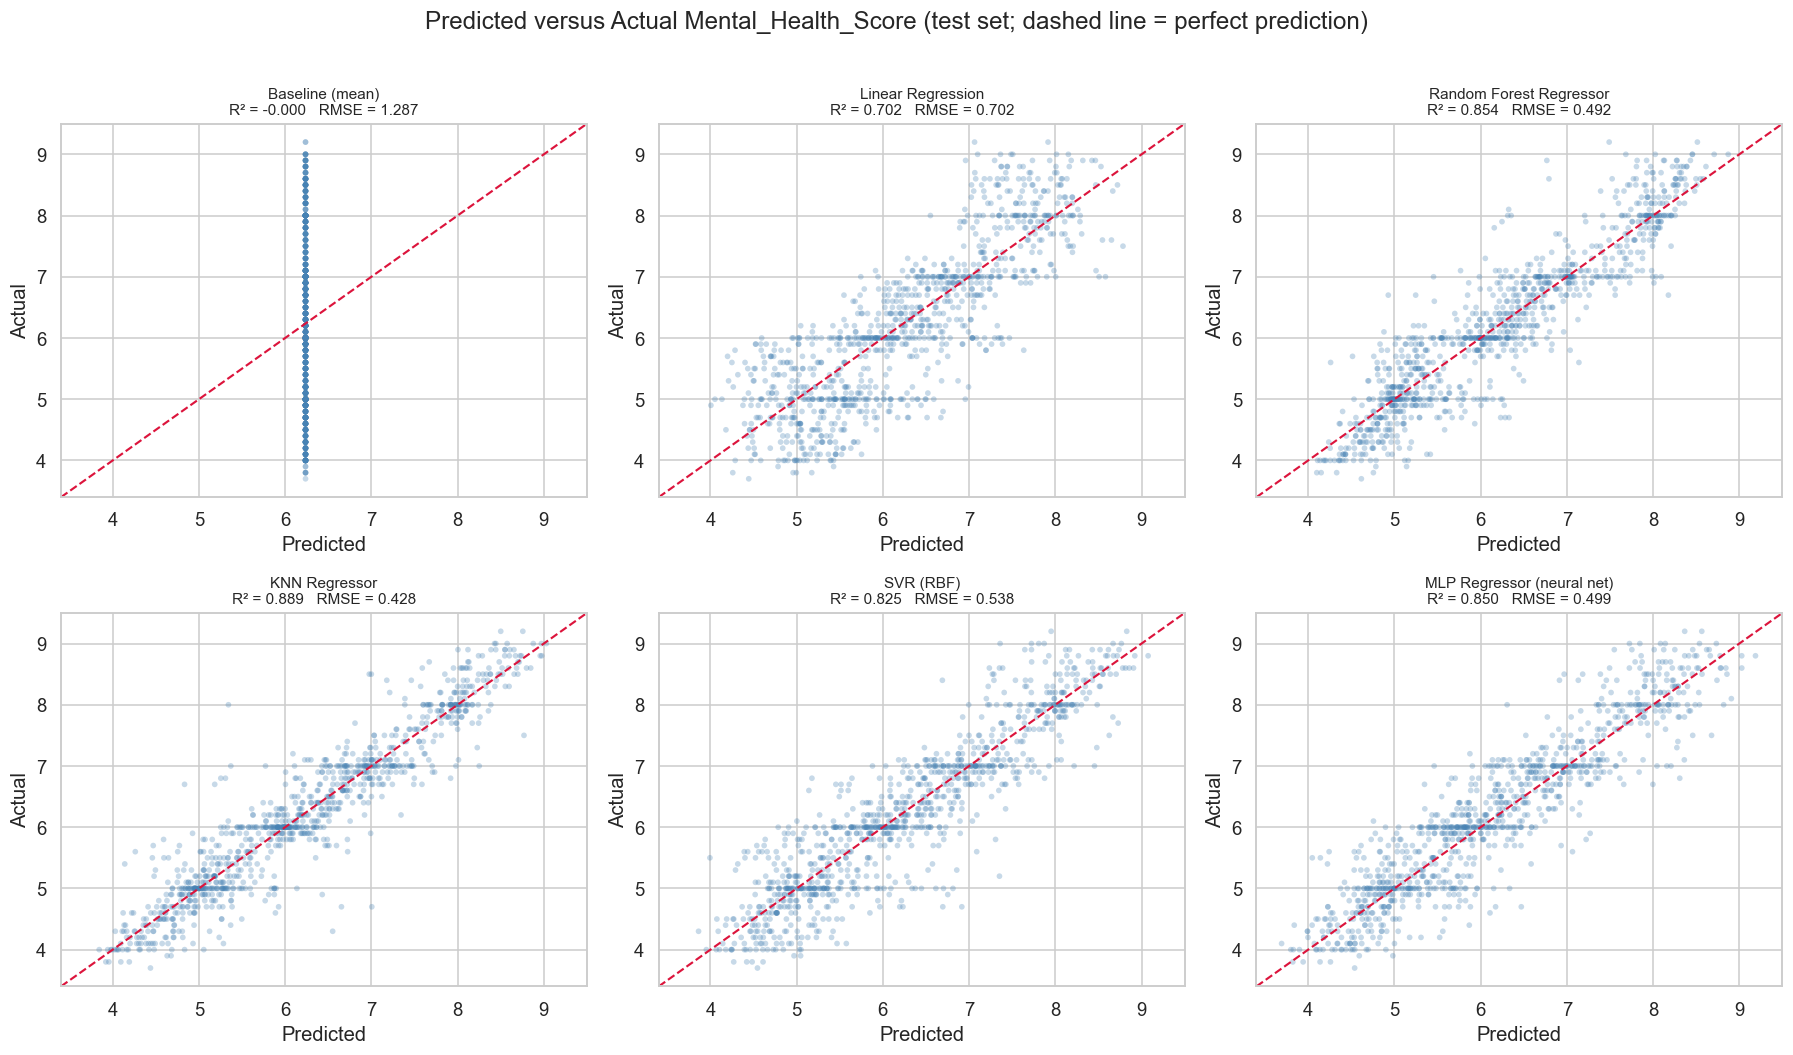

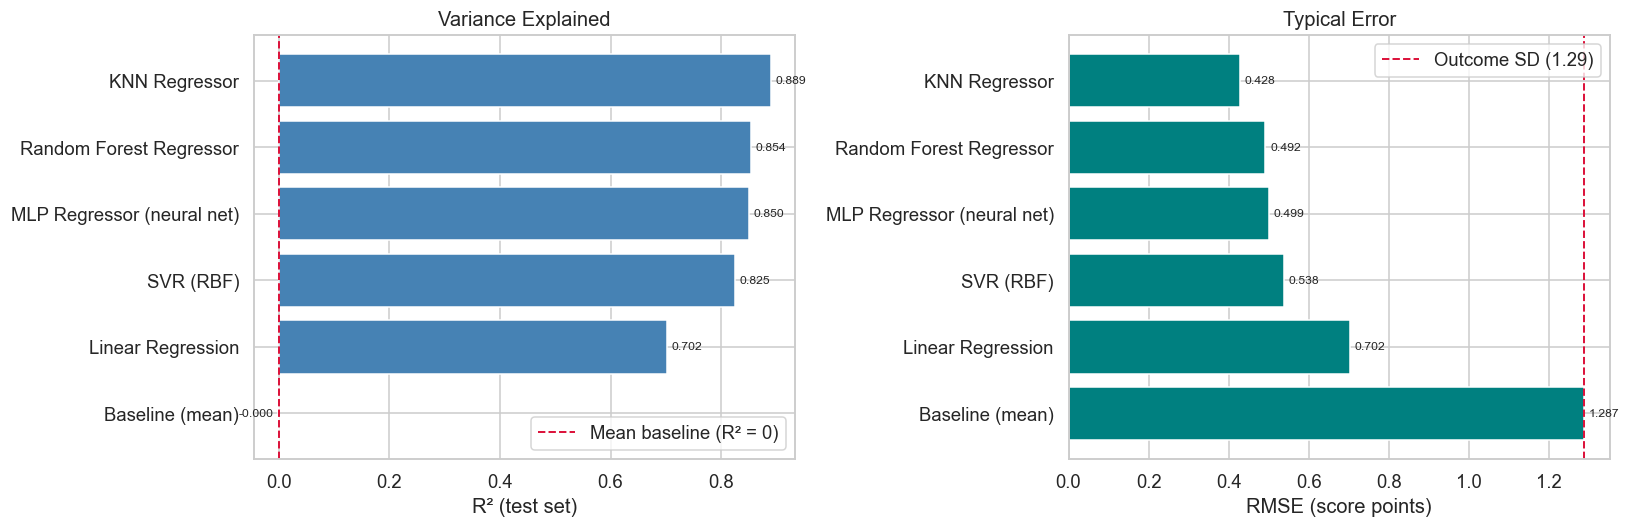

In [187]:
# --- F9 + F11: predicted vs actual, and the metric summary -------------------
fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.5))
lims = (y_reg_test.min() - 0.3, y_reg_test.max() + 0.3)
for ax, (label, *_ ) in zip(axes.ravel(), REG_MODELS):
    pred = reg_preds[label]
    ax.scatter(pred, y_reg_test, alpha=0.3, s=14, color='steelblue', edgecolors='none')
    ax.plot(lims, lims, color='crimson', linestyle='--', lw=1.4)
    r2 = res_reg.loc[res_reg['Model'] == label, 'R²'].iat[0]
    rmse = res_reg.loc[res_reg['Model'] == label, 'RMSE'].iat[0]
    ax.set_title(f'{label}\nR² = {r2:.3f}   RMSE = {rmse:.3f}', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_xlim(lims); ax.set_ylim(lims)

fig.suptitle(f'Predicted versus Actual {MHS_COL} (test set; dashed line = perfect prediction)',
             y=1.01)
plt.tight_layout(); plt.show()

order = res_reg['Model'].tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(order[::-1], res_reg['R²'].to_numpy()[::-1], color='steelblue', edgecolor='white')
axes[0].axvline(0, color='crimson', linestyle='--', lw=1.3, label='Mean baseline (R² = 0)')
axes[0].set_xlabel('R² (test set)'); axes[0].set_title('Variance Explained'); axes[0].legend()
axes[1].barh(order[::-1], res_reg['RMSE'].to_numpy()[::-1], color='teal', edgecolor='white')
axes[1].axvline(y_reg_test.std(), color='crimson', linestyle='--', lw=1.3,
                label=f'Outcome SD ({y_reg_test.std():.2f})')
axes[1].set_xlabel('RMSE (score points)'); axes[1].set_title('Typical Error'); axes[1].legend()
for ax in axes:
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.3f', fontsize=8, padding=3)
plt.tight_layout(); plt.show()

**Figure 12** — residuals vs fitted values, and the residual distribution, for our best regressor.

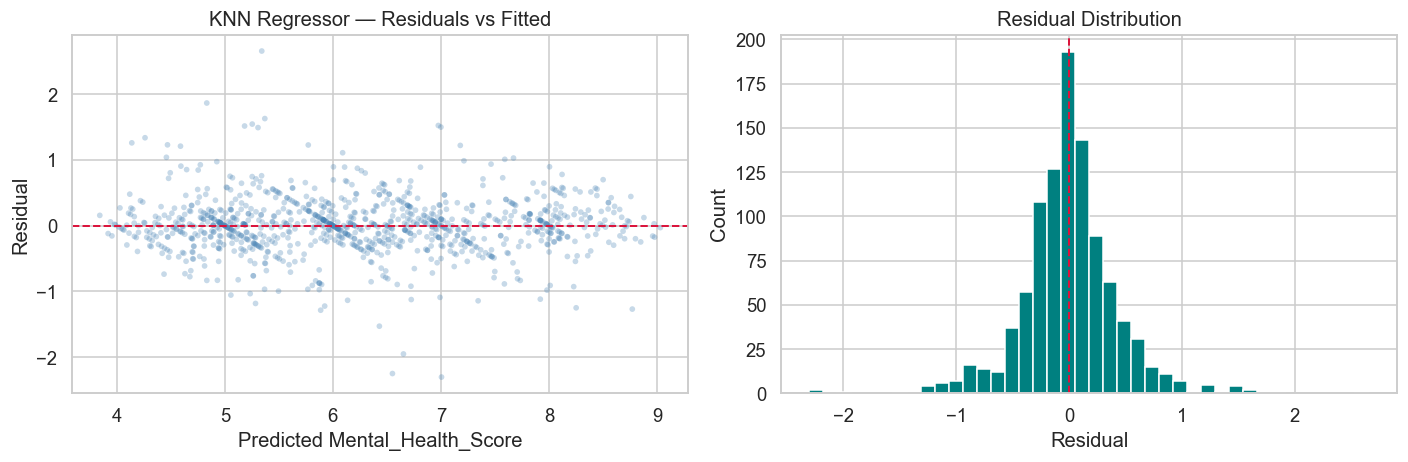

Residual mean = +0.0019, SD = 0.4284
Within ±0.5 score points: 82.5%   within ±1.0: 96.6%


In [188]:
# --- F10: residual diagnostics for the best regressor -----------------------
BEST_REG = res_reg['Model'].iat[0]
resid = y_reg_test - reg_preds[BEST_REG]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].scatter(reg_preds[BEST_REG], resid, alpha=0.3, s=14, color='steelblue', edgecolors='none')
axes[0].axhline(0, color='crimson', linestyle='--', lw=1.3)
axes[0].set_xlabel(f'Predicted {MHS_COL}'); axes[0].set_ylabel('Residual')
axes[0].set_title(f'{BEST_REG} — Residuals vs Fitted')

axes[1].hist(resid, bins=40, color='teal', edgecolor='white')
axes[1].axvline(0, color='crimson', linestyle='--', lw=1.3)
axes[1].set_xlabel('Residual'); axes[1].set_ylabel('Count')
axes[1].set_title('Residual Distribution')
plt.tight_layout(); plt.show()

print(f'Residual mean = {resid.mean():+.4f}, SD = {resid.std():.4f}')
print(f'Within ±0.5 score points: {(np.abs(resid) <= 0.5).mean():.1%}   '
      f'within ±1.0: {(np.abs(resid) <= 1.0).mean():.1%}')

The mental-health score is predictable too. **KNN Regressor is our best model** with R² 0.8892,
MSE 0.1835, RMSE 0.4284 and MAE 0.2955. Then Random Forest 0.8540, MLP 0.8495, SVR 0.8251, Linear
Regression 0.7023, and the mean baseline at −0.0004.

**We see the same linear vs non-linear split again,** which is why we trust it. Linear regression explains
70.2% of the variance and every non-linear model beats it, the best by nearly **19% of R²**. Two
different tasks, two different sets of metrics, the same conclusion: the relationships in our data are
curved.

In the units of the score, RMSE 0.4284 against a test SD of 1.2868 means our typical error is about a
third of the natural spread. MAE 0.2955 says it more simply: on a scale from 3.6 to 9.4 we are usually
within about three tenths of a point.

The residuals look fine — mean +0.0019 (so no much bias), 82.5% of students within ±0.5 points and 96.6% within
±1.0, and no funnel or curve in the residual plot, so we are not systematically wrong at either end.

**KNN winning here is the opposite of the classification task**, where it came last among the non-linear
models. We think this makes sense: the score is a smooth continuous surface, and averaging the 4 most
similar students in standardised 23-dimensional space is a good strategy for a smooth surface. The same
locality that blurs a 4-way boundary helps when the answer is a number.

The wider grid is what found that neighbourhood. With the L1 (manhattan) norm and k = 4 distance-weighted
neighbours it reaches R² 0.8892, against 0.8784 for the k = 5 euclidean setting our original 6-point grid
was limited to — about 1 extra point of explained variance purely from searching the distance measure.

## 4. Discussion

### 4.1 What we found

- **Both targets are predictable.** Stress: 0.914 accuracy against a 0.324 baseline. Mental-health score:
  R² 0.889 against a baseline of ~0.
- **Non-linear beats linear, in both tasks.** Logistic regression 0.743 vs 0.913 for the best classifier;
  linear regression R² 0.702 vs 0.889. Searching l1 / l2 / elasticnet / no penalty (16 points) did not
  move it at all — the limit is the straight line, not the tuning.
- **Trees won on Set A but not on Set B.** Set A: XGBoost 0.810, Random Forest 0.767 (1st and 2nd, as we
  expected). Set B: KNN 0.913, Random Forest 0.888, XGBoost 0.886. Trees are the better default for
  categorical dummies and lose that edge once smooth numeric columns are added. Random Forest is still
  the best individual model on macro AUC (0.9850).
- **The feature set matters more than the algorithm.** Set A → Set B gains run from +0.023 (logistic
  regression) to +0.175 (hard vote), against only 3.5 accuracy points between the individual non-linear
  models within Set B.
- **Accuracy and AUC disagree.** The tuned KNN is 1-nearest-neighbour, so its probabilities are only 0 or
  1: best macro F1 of any model (0.9096) and second-best accuracy, but macro AUC 0.9378 — worse than
  every real model except logistic regression.
- **Ensembling gained one student.** Soft vote 0.914 vs KNN 0.913, one of its own members. Soft beats
  hard by 8 students; they agree on 96.6% of the test set.
- **Mistakes are adjacent.** Mean error 0.087 levels, 99.9% within one level, 1 student in 1 000 off by
  two or more.
- **The country test contradicted us.** We expected validation-only overfitting; the gain held on the
  test set (+0.016 Random Forest, +0.022 soft vote). We still exclude `Country`, for the research
  question rather than for accuracy.

### 4.2 Why the numbers are too good

A single nearest neighbour classifies 91.3% of unseen students correctly, and adding
`Mental_Health_Score` to the features did not help at all (2.3.1). With Q1 (r = −0.82) and Q7 (ρ = −0.82)
pointing the same way, this looks like generated data driven by one hidden factor rather than independent
self-reports. The comparison between models is still valid — every model faced the same task — but the
absolute numbers are not a finding about real students.

## 5. Limitations

- **Scores do not transfer** — see 4.2.
- **No single best algorithm.** Top three within 8 students, and best-by-accuracy (soft vote),
  best-by-AUC (Random Forest) and best-by-F1 (KNN) are three different models.
- **Unequal search budgets.** KNN 180 grid points and Random Forest 175, against SVM 6 and MLP 4. KNN
  finished *last* among the non-linear models with its old 6-point grid and second after widening, so
  part of the ranking may be tuning effort rather than model quality.
- **One 60/20/20 split, one seed.** Models finishing this close together could reorder on another split.
- **Dropping `Country`** cost 1.6 (Random Forest) and 2.2 (soft vote) test-accuracy points, and the gain
  replicated out of sample.
- **The ensembles have a small unfair advantage** — their members inherit hyperparameters tuned on the
  same validation set the ensembles are then refit against.

## 6. Our answer to Research Question 8

> **Can we predict the stress level and the mental-health score of a social-network user from their
> social-media usage characteristics?**

**Yes, on both.**

| Target | Best model | Result | Baseline |
|---|---|---|---|
| `Stress_Level` (4 levels) | Ensemble (soft vote) | accuracy **0.914**, macro F1 **0.909**, macro AUC **0.9893** | 0.324 |
| `Mental_Health_Score` | KNN Regressor | R² **0.889**, RMSE **0.428**, MAE **0.296** | R² ≈ 0.000 |

- **Expectation 1 — the features beat the baselines:** confirmed, by 59 accuracy points and 88.9% of the
  variance.
- **Expectation 2 — non-linear beats linear:** confirmed on both tasks.
- **Expectation 3 — trees score highest:** only on Set A. On Set B a 1-nearest-neighbour model wins and
  the trees finish 2nd and 3rd.
- **On usage characteristics alone** (Set A) we already reach 0.810
  accuracy and 0.9587 macro AUC; the lifestyle and demographic block adds up to 17.5 points on top.
- **Caveat:** this dataset behaves as if generated from one hidden factor, so these absolute numbers
  would not hold for real students (4.2).